# TP Integrador — Modulación LoRa / FSCM

Grupo 8 — **Testigos de Vangelista**.

Integrantes:

- Castro, Victor José Arturo 
- Carreras, Leonor Victoria


## Índice

**[1. Transmisor](#transmisor)**
- [Parámetros del sistema](#parametros)
- [De bits a símbolos](#bits)
- [Modulación con chirps](#modulacion)
- [Preámbulo en el dominio del tiempo](#preambulo)
- [Densidad espectral de potencia del preámbulo](#psd-preambulo)
- [Trama completa en el dominio del tiempo](#trama)
- [Densidad espectral de potencia de la trama](#psd-trama)
- [Demodulación](#demodulacion)
- [Armado de la trama](#armado)

**[2. Detección del preámbulo](#deteccion)**
- [Modelo de la captura (simulación)](#captura)
- [Detector en el tiempo: correlación normalizada](#det-tiempo)
- [Umbral de decisión: criterio de Neyman–Pearson](#umbral)
- [La decisión sobre una captura](#decision)
- [Detector en frecuencia: qué dice el bin de una ventana](#bin)
- [Criterio 7 de 8 y ubicación del inicio](#criterio)
- [Las 8 ventanas del bloque detectado](#ventanas)

**[3. Desempeño en simulación: FER y BER](#desempeno)**
- [Detección y FER contra la SNR](#fer)
- [BER contra la SNR](#ber)

**[4. Enlace real con el ADALM-Pluto](#enlace)**
- [Configuración del SDR](#config-sdr)
- [Envío de la trama](#envio)
- [Señal recibida en el dominio del tiempo](#senal-rx)
- [Densidad espectral de potencia de la señal recibida](#psd-rx)
- [Demodulación del payload recibido](#demod-rx)
- [FER en el enlace real](#fer-real)
- [Cierre del enlace](#cierre)



In [1]:
import numpy as np
import matplotlib.pyplot as plt

**Librerías**

Todo el trabajo se apoya en dos librerías: `numpy`, para generar y procesar las señales como vectores, y `matplotlib`, para graficarlas. Las señales nunca se recorren muestra por muestra: se operan completas, lo que hace el código más corto y más rápido. La librería que controla el SDR se importa recién en la sección del enlace, así que el transmisor y la simulación pueden ejecutarse sin tener la placa conectada.

<a id="transmisor"></a>

## 1. Transmisor


In [2]:
# TRANSMISOR — 1. Parámetros del PHY y del preámbulo

SF = 8                          # bits por símbolo
SamplingRate = 1_000_000        # tasa del SDR [muestras/s]
B = SamplingRate                # el chirp barre exactamente la tasa de muestreo
M = 2 ** SF                     # muestras por símbolo = símbolos posibles
T = 1 / B                       # período de chip [s]
Ts = M * T                      # duración de un símbolo [s]
k = np.arange(M)                # índice de chip

fc = 915e6                      # portadora dentro de la banda 900-920 MHz

n_up = 8                        # up-chirps del preámbulo
n_down = 2                      # down-chirps completos
cuarto_down = True              # último 1/4 de down-chirp
n_simbolos = 10                 # símbolos del payload

tramas_en_buffer = 2            # tramas por captura del receptor
P_FA = 1e-3                     # falsas alarmas aceptadas por el detector en el tiempo
n_capturas_fer = 50_000         # capturas por punto de SNR en la FER simulada
snr_fer_db = np.arange(-24, -3, 2)   # SNR = 10*log10(Ps/Pn) por muestra [dB]
semilla = 2024

print(f"SF = {SF} | M = {M} | B = {B/1e6:.3f} MHz | fc = {fc/1e6:.0f} MHz")
print(f"Símbolo = {Ts*1e6:.1f} µs | Preámbulo = {(n_up + n_down)*M + (M//4 if cuarto_down else 0)} muestras")
print(f"Detección: P_FA = {P_FA:g} | FER: {n_capturas_fer} capturas por punto, SNR de {snr_fer_db[0]} a {snr_fer_db[-1]} dB")

SF = 8 | M = 256 | B = 1.000 MHz | fc = 915 MHz
Símbolo = 256.0 µs | Preámbulo = 2624 muestras
Detección: P_FA = 0.001 | FER: 50000 capturas por punto, SNR de -24 a -4 dB


<a id="parametros"></a>

**Parámetros del sistema**

Acá se fijan los valores que comparten el transmisor y el receptor. El más importante es el factor de ensanchamiento `SF = 8`: cada símbolo transporta 8 bits, hay `M = 256` símbolos posibles y cada uno dura 256 muestras. El chirp ocupa 1 MHz, la misma tasa a la que muestrea el SDR, y se transmite en 915 MHz. El preámbulo, que el receptor usa para encontrar el comienzo de cada trama, está formado por 8 chirps ascendentes, 2 descendentes y un cuarto de chirp descendente. Todos los valores derivados se calculan a partir de `SF`, de modo que al cambiarlo se ajusta el resto del sistema.

In [3]:
# TRANSMISOR — 2. De bits a símbolo (Ecuación 1)
def bits_a_simbolo(bits, SF=SF):
    """Convierte filas de bits (LSB primero) en símbolos enteros."""
    simbolos = []
    for fila in np.asarray(bits):
        fila = np.asarray(fila, dtype=np.int64).ravel()
        if fila.size != SF:
            raise ValueError("cada fila debe tener SF bits")
        simbolos.append(int(np.dot(fila, 2 ** np.arange(SF))))
    return np.asarray(simbolos)


generador_bits = np.random.default_rng(semilla)
bits_payload = generador_bits.integers(0, 2, size=(n_simbolos, SF))
simbolos_payload = bits_a_simbolo(bits_payload)

print("Bits del payload (LSB primero) -> símbolo:")
for fila, simbolo in zip(bits_payload, simbolos_payload):
    print(f"  {fila.tolist()} -> {simbolo:3d}")

Bits del payload (LSB primero) -> símbolo:
  [0, 1, 0, 0, 0, 0, 1, 1] -> 194
  [1, 1, 0, 0, 1, 0, 0, 0] ->  19
  [1, 0, 0, 0, 0, 1, 1, 1] -> 225
  [1, 0, 0, 1, 1, 0, 0, 0] ->  25
  [0, 1, 1, 1, 1, 1, 0, 0] ->  62
  [0, 0, 1, 0, 1, 0, 1, 1] -> 212
  [1, 0, 0, 0, 1, 1, 0, 0] ->  49
  [0, 0, 0, 0, 1, 0, 1, 0] ->  80
  [0, 1, 1, 0, 0, 1, 0, 0] ->  38
  [0, 0, 0, 1, 0, 1, 0, 0] ->  40


<a id="bits"></a>

**De bits a símbolos**

El mensaje a transmitir empieza siendo una secuencia de bits aleatorios. Se agrupan de a 8, y cada grupo se convierte en un número entre 0 y 255 según la ecuación (1) del paper, tomando el primer bit como el menos significativo. Ese número es el símbolo que después se va a modular. Los bits se generan con una semilla fija, así que cada ejecución produce el mismo mensaje y los resultados se pueden repetir.

In [4]:
# TRANSMISOR — 3. Modulación de símbolo (Ecuaciones 2 y 3)
def up_chirp(M=M):
    """Chirp ascendente base, energía unitaria."""
    kk = np.arange(M)
    return (1.0 / np.sqrt(M)) * np.exp(1j * 2 * np.pi * (kk ** 2) / M)


def down_chirp(M=M):
    """Chirp descendente: el conjugado del ascendente."""
    return np.conj(up_chirp(M))


def down_chirp_demod(M=M):
    """Réplica usada para dechirpear (sin la escala 1/sqrt(M))."""
    kk = np.arange(M)
    return np.exp(-1j * 2 * np.pi * (kk ** 2) / M)


def modular(simbolos, M=M):
    """Genera la señal FSCM de una secuencia de símbolos."""
    kk = np.arange(M)
    partes = []
    for simbolo in np.asarray(simbolos).ravel():
        if not 0 <= int(simbolo) < M:
            raise ValueError(f"símbolo fuera de rango: {simbolo}")
        fase = 2 * np.pi * (((int(simbolo) + kk) % M) * kk) / M
        partes.append((1 / np.sqrt(M)) * np.exp(1j * fase))
    return np.concatenate(partes)


def preambulo(M=M, n_up=n_up, n_down=n_down, cuarto=cuarto_down):
    """Preámbulo: up-chirps, down-chirps y 1/4 de down-chirp."""
    partes = [np.tile(up_chirp(M), n_up)]
    if n_down:
        partes.append(np.tile(down_chirp(M), n_down))
    if cuarto:
        partes.append(down_chirp(M)[: M // 4])
    return np.concatenate(partes)


def longitud_preambulo(M=M, n_up=n_up, n_down=n_down, cuarto=cuarto_down):
    largo = n_up * M + n_down * M
    if cuarto:
        largo += M // 4
    return largo

<a id="modulacion"></a>

**Modulación con chirps**

LoRa representa cada símbolo con un chirp: una señal cuya frecuencia crece linealmente y recorre toda la banda. Lo que distingue a un símbolo de otro es la frecuencia en la que arranca el barrido; al llegar al borde superior, la frecuencia vuelve a empezar desde abajo. Gracias a eso los 256 chirps posibles son ortogonales entre sí y el receptor puede distinguirlos sin ambigüedad (ecuaciones (2) y (3)). En este bloque se definen el chirp ascendente base, el descendente, la función que modula una secuencia de símbolos y la que arma el preámbulo. La señal queda en banda base: la portadora de 915 MHz la agrega el SDR.

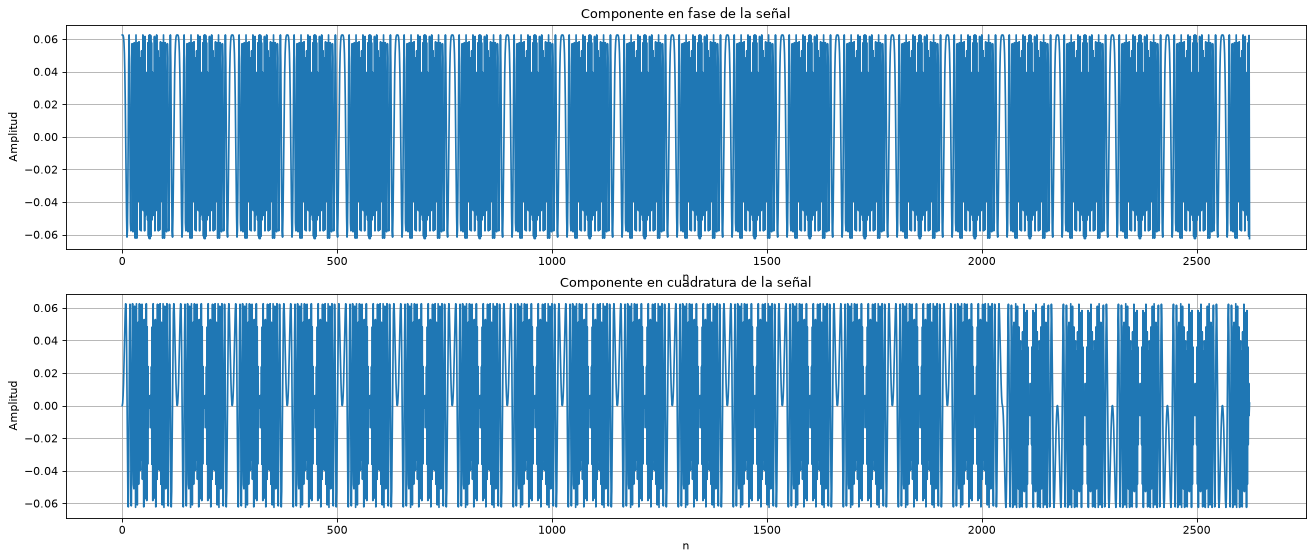

In [5]:
# TRANSMISOR — 4. Gráfico de la señal del preámbulo
def plotSignal(signal):
    #------------------------------- Componente en fase -------------------------------
    plt.figure(figsize=(20, 8), dpi=80, facecolor="w", edgecolor="k")
    plt.subplot(2, 1, 1)
    plt.plot(np.real(signal))
    plt.xlabel("n")
    plt.ylabel("Amplitud")
    plt.title("Componente en fase de la señal")
    plt.grid()
    #------------------------------- Componente en cuadratura ------------------------
    plt.subplot(2, 1, 2)
    plt.plot(np.imag(signal))
    plt.xlabel("n")
    plt.ylabel("Amplitud")
    plt.title("Componente en cuadratura de la señal")
    plt.grid()
    plt.show()


preambulo_ref = preambulo()
plotSignal(preambulo_ref)

<a id="preambulo"></a>

**Preámbulo en el dominio del tiempo**

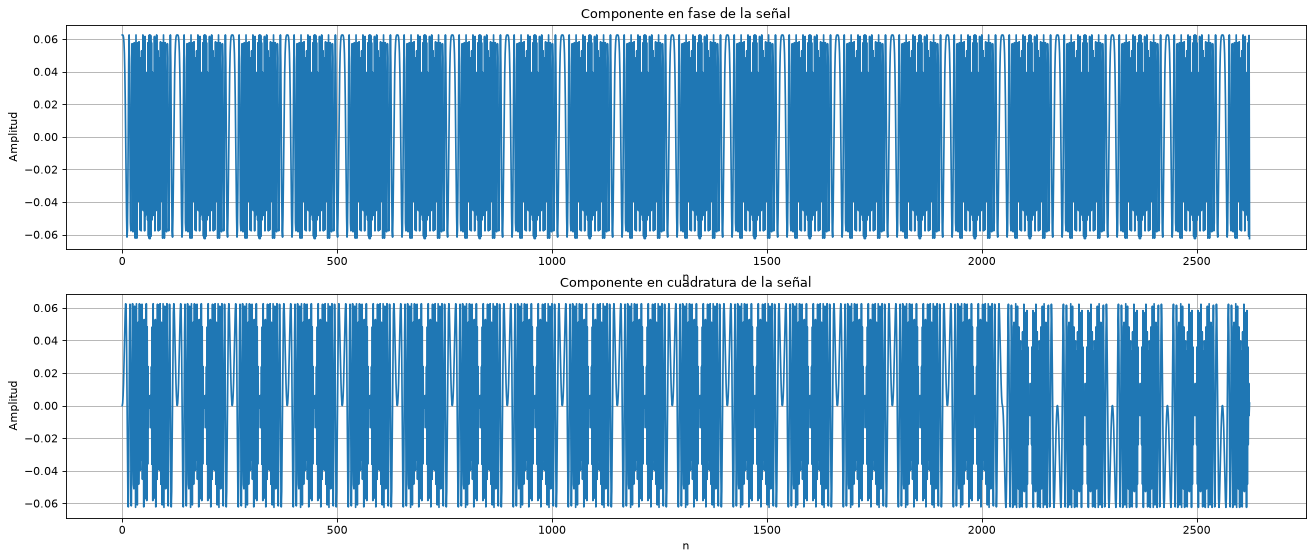

Se muestran las componentes en fase y en cuadratura del preámbulo. La amplitud se mantiene aproximadamente constante y lo que cambia es la frecuencia instantánea: el chirp barre la banda de forma lineal. La forma de onda corresponde a las ecuaciones (2)-(3) del paper, particularizadas para los símbolos del preámbulo. Sirve para verificar que la señal se construyó bien antes de agregar el payload.


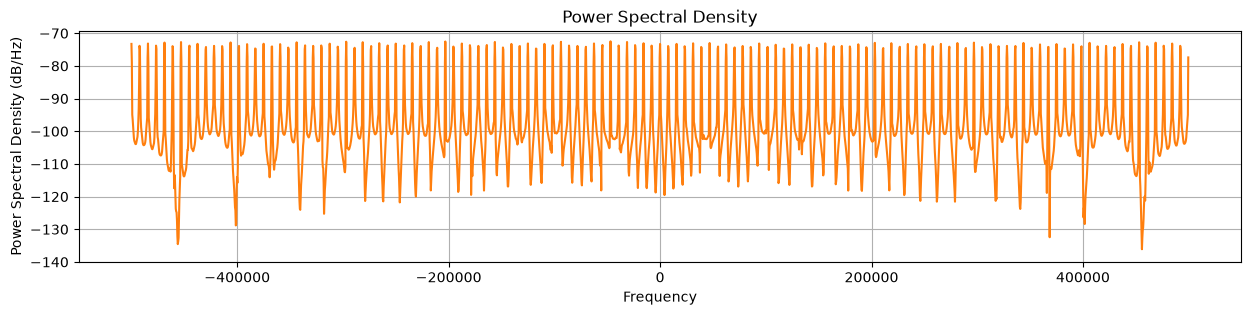

In [6]:
# TRANSMISOR — 5. Densidad espectral de potencia del preámbulo
def plotSpect(signal, samplingRate):
    plt.subplots(figsize=(15, 3))
    plt.grid()
    plt.title("Power Spectral Density")
    plt.psd(signal, NFFT=len(signal), Fs=samplingRate, color="C1")
    plt.show()


plotSpect(preambulo_ref, SamplingRate)

<a id="psd-preambulo"></a>

**Densidad espectral de potencia del preámbulo**

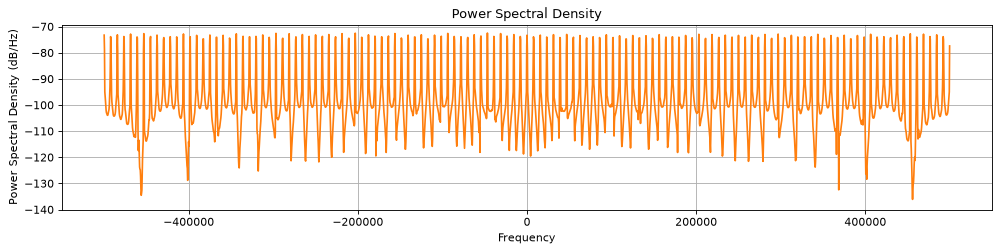

La PSD del preámbulo ocupa aproximadamente la banda de 1 MHz centrada en la portadora. El chirp recorre todas las frecuencias de la banda, por eso el espectro es bastante plano y no se concentra en unas pocas líneas. Es una consecuencia directa de la forma de onda de las ecuaciones (2)-(3). Confirma que la modulación no se sale de la banda útil.


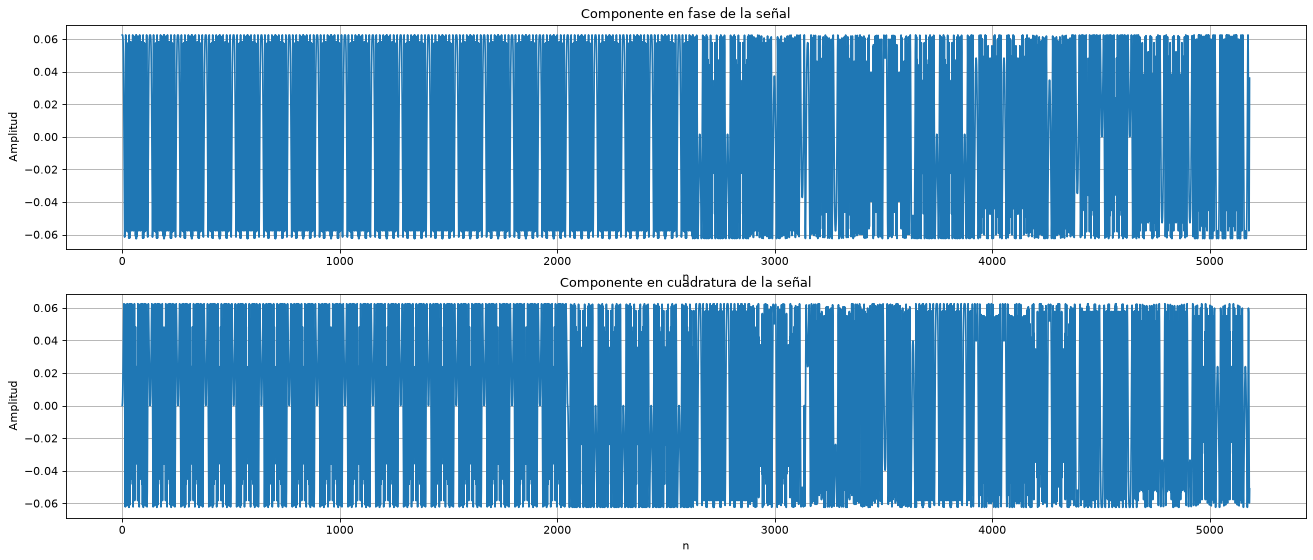

In [7]:
# TRANSMISOR — 6. Gráfico de la señal completa (trama)
trama = np.concatenate([preambulo_ref, modular(simbolos_payload)])
plotSignal(trama)

<a id="trama"></a>

**Trama completa en el dominio del tiempo**

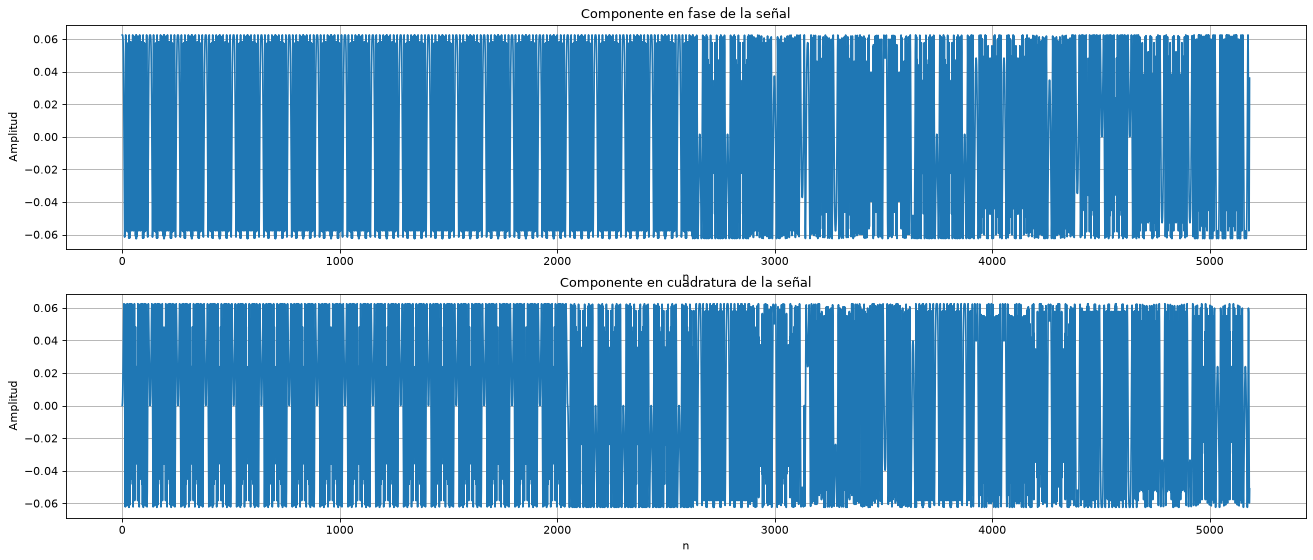

Ahora se grafica la trama completa: el preámbulo seguido por los símbolos del payload. Cada símbolo es un chirp con un desplazamiento cíclico de frecuencia, de acuerdo con la ecuación (1) para el símbolo y las ecuaciones (2)-(3) para la forma de onda. La envolvente sigue siendo aproximadamente constante; los cambios de fase entre símbolos son esperables. Esta es la señal que el transmisor repite de forma cíclica.


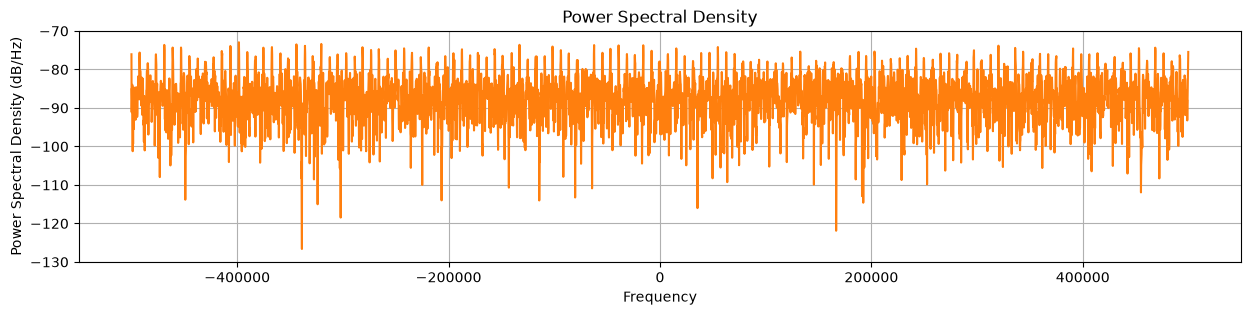

In [8]:
# TRANSMISOR — 7. Densidad espectral de potencia de la trama completa
plotSpect(trama, SamplingRate)

<a id="psd-trama"></a>

**Densidad espectral de potencia de la trama**

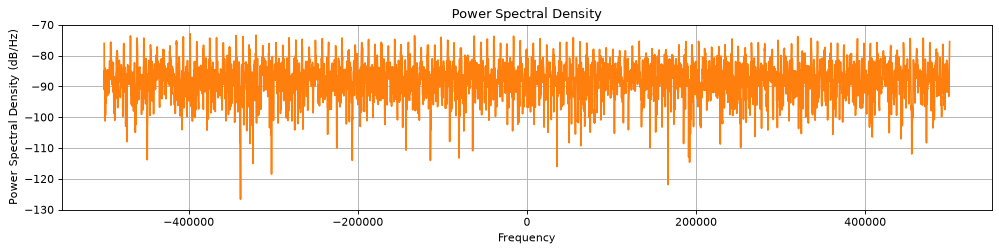

La PSD de la trama completa es prácticamente igual a la del preámbulo: agregar payload no ensancha la banda ni genera componentes fuera de 1 MHz. El payload también está formado por chirps, así que la ocupación espectral queda determinada por las ecuaciones (2)-(3). Sirve para confirmar que la trama completa sigue siendo compatible con el ancho de banda del canal.


In [9]:
# TRANSMISOR — 8. Demodulación (Ecuaciones 15 y 16)
def demodular(recibido, M=M):
    """Demodula uno o varios símbolos por dechirp + FFT."""
    datos = np.asarray(recibido, dtype=np.complex128)
    if datos.ndim == 1:
        if datos.size % M != 0:
            raise ValueError("la señal no es múltiplo de M")
        datos = datos.reshape(-1, M)
    dechirpeado = datos * down_chirp_demod(M)[None, :]
    espectros = np.abs(np.fft.fft(dechirpeado, axis=1))
    return np.argmax(espectros, axis=1)


simbolos_recuperados = demodular(modular(simbolos_payload))
print("Demodulación ida y vuelta:", np.array_equal(simbolos_recuperados, simbolos_payload))

Demodulación ida y vuelta: True


<a id="demodulacion"></a>

**Demodulación**

Para recuperar un símbolo, el receptor multiplica el chirp recibido por un chirp descendente. Esa operación, llamada *dechirp*, cancela el barrido de frecuencia y deja un tono puro cuya frecuencia coincide con el valor del símbolo. Después se calcula la FFT y se busca el pico más alto: su posición es el símbolo transmitido (ecuaciones (15) y (16)). Como prueba, el payload se modula y se demodula sin ruido; el resultado `True` confirma que se recuperan exactamente los mismos símbolos.

In [10]:
# TRANSMISOR — 9. Armado de la trama: preámbulo + payload
def construir_trama(simbolos, M=M, n_up=n_up, n_down=n_down, cuarto=cuarto_down):
    """Preámbulo seguido del payload modulado."""
    return np.concatenate([preambulo(M, n_up, n_down, cuarto), modular(simbolos, M)])


def longitud_trama(M=M, n_simbolos=n_simbolos, n_up=n_up, n_down=n_down,
                   cuarto=cuarto_down):
    return longitud_preambulo(M, n_up, n_down, cuarto) + n_simbolos * M


trama = construir_trama(simbolos_payload)
print(f"Preámbulo: {preambulo_ref.size} muestras")
print(f"Payload:   {n_simbolos*M} muestras")
print(f"Trama:     {trama.size} muestras ({trama.size/SamplingRate*1e3:.3f} ms)")

Preámbulo: 2624 muestras
Payload:   2560 muestras
Trama:     5184 muestras (5.184 ms)


<a id="armado"></a>

**Armado de la trama**

La trama es lo que efectivamente se envía: el preámbulo seguido de los 10 símbolos del mensaje. Con los parámetros elegidos, el preámbulo ocupa 2624 muestras y el payload 2560, en total 5184 muestras, unos 5 ms de señal. Esta trama todavía no tiene ruido, portadora ni escalado para el SDR: es la señal ideal que sale del transmisor.

<a id="deteccion"></a>

## 2. Detección del preámbulo


In [11]:
# DETECCIÓN — 1. Modelo de la captura del receptor (simulación)
import time

P = longitud_preambulo()                     # 2624 muestras de preámbulo
L = longitud_trama()                         # 5184 muestras de trama
PRE = preambulo_ref.astype(np.complex64)     # patrón que conoce el receptor
DECHIRP = down_chirp_demod(M).astype(np.complex64)
h_flat = np.array([1.0])                                 # canal FLAT
h_selectivo = np.array([np.sqrt(0.8), np.sqrt(0.2)])     # canal selectivo (2 taps)


def generar_captura(snr_db, generador, con_trama=True, h=h_flat):
    """Captura de 2 tramas de un TX cíclico, tomada en un instante al azar.
    Devuelve (captura, inicio real en [0, L) o -1 si no hay trama, símbolos del payload)."""
    simbolos = generador.integers(0, M, n_simbolos)
    if con_trama:
        tx = np.tile(construir_trama(simbolos), 4)          # el TX repite la trama sin pausa
        tx = np.convolve(tx, h)[: tx.size]                  # canal por convolución
        desfase = int(generador.integers(0, L))             # instante de captura al azar
        captura_sim = tx[L + desfase: L + desfase + 2 * L].astype(np.complex64)
        inicio = (L - desfase) % L
    else:
        captura_sim = np.zeros(2 * L, np.complex64)
        inicio = -1
    sigma = np.sqrt((1 / M) / 10 ** (snr_db / 10) / 2)      # Ps = 1/M, Pn = 2*sigma^2
    ruido = generador.standard_normal(2 * L) + 1j * generador.standard_normal(2 * L)
    return captura_sim + (sigma * ruido).astype(np.complex64), inicio, simbolos


x_ej, inicio_ej, _ = generar_captura(-15, np.random.default_rng(semilla + 1))
print(f"Captura simulada: {x_ej.size} muestras (2 tramas) | la trama empieza en {inicio_ej}")


Captura simulada: 10368 muestras (2 tramas) | la trama empieza en 3182


<a id="captura"></a>

**Modelo de la captura (simulación)**

El receptor no sabe en qué momento empieza cada trama: tiene que decidir **si hay una trama** en la captura y **dónde empieza**. Para evaluarlo sin usar el Pluto se simula lo mismo que pasa en el enlace real: el transmisor repite la trama sin pausa y el receptor captura `2·L = 10 368` muestras a partir de un instante al azar. Así siempre queda una trama completa adentro, que empieza en una posición desconocida entre `0` y `L − 1`; el simulador la conoce y puede verificar si el detector acertó. Cada captura lleva un payload aleatorio, pasa por el canal (convolución con `h`, FLAT o selectivo) y se le suma ruido gaussiano complejo con `SNR = Ps/Pn` por muestra (ecuación (10)).

Se comparan dos detectores, cada uno con su criterio de decisión:

| | Detector en el tiempo | Detector en frecuencia |
|---|---|---|
| Qué hace | Correlación normalizada del preámbulo con la captura, muestra a muestra | Demodula ventanas de 256 muestras (dechirp + FFT) |
| Criterio | Máximo de ρ ≥ umbral γ, con γ elegido por **Neyman–Pearson** | **7 de 8** ventanas seguidas con el mismo bin |


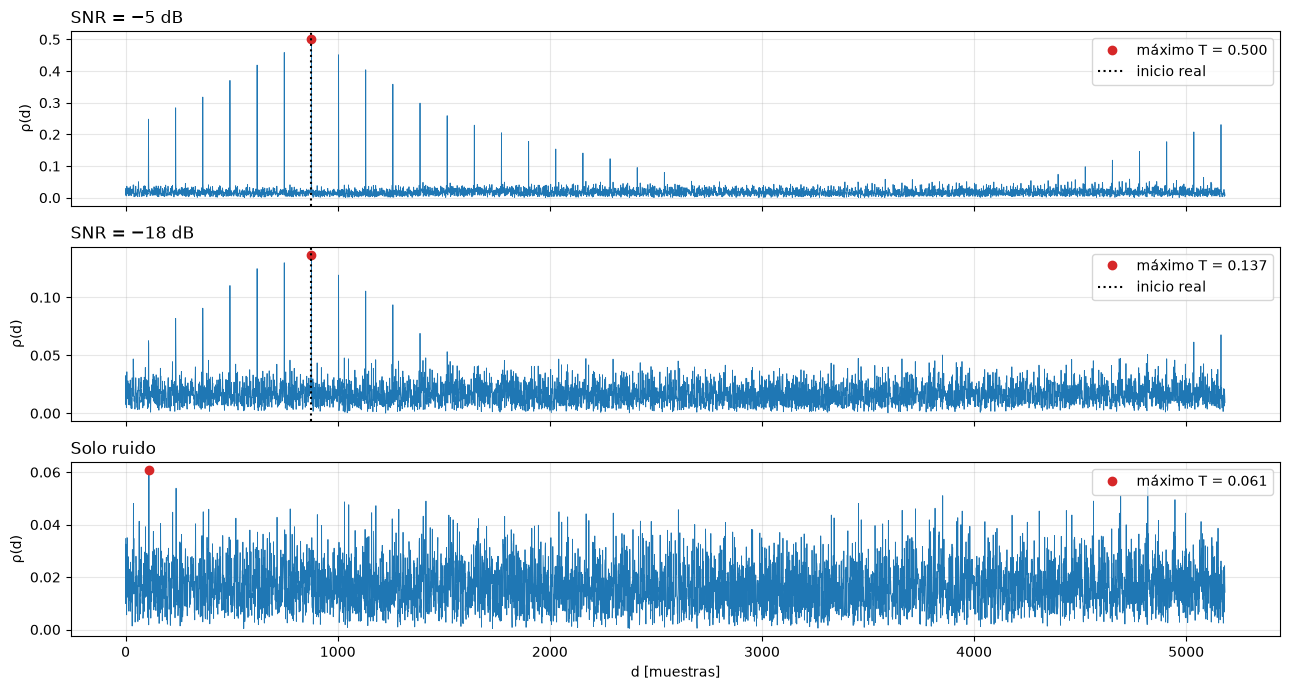

In [12]:
# DETECCIÓN — 2. Detector en el tiempo: correlación normalizada
def correlacion_normalizada(captura_in, patron=PRE, n_pos=L):
    """rho(d) para d = 0 .. n_pos-1, por correlación directa (np.correlate)."""
    seg = captura_in[: n_pos + patron.size - 1]
    numerador = np.abs(np.correlate(seg, patron, mode="valid"))
    acum = np.concatenate(([0.0], np.cumsum(np.abs(seg) ** 2)))
    energia_ventana = acum[patron.size:] - acum[:-patron.size]
    return numerador / (np.linalg.norm(patron) * np.sqrt(energia_ventana) + 1e-12)


def detector_tiempo(captura_in, gamma):
    """Devuelve (inicio estimado o -1 si no hay trama, T = máximo de rho)."""
    rho = correlacion_normalizada(captura_in)
    d = int(np.argmax(rho))
    return (d if rho[d] >= gamma else -1), float(rho[d])


casos = [("SNR = −5 dB", -5, True), ("SNR = −18 dB", -18, True), ("Solo ruido", -18, False)]
fig, ejes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
for eje, (titulo, snr, con) in zip(ejes, casos):
    x, ini, _ = generar_captura(snr, np.random.default_rng(semilla + 2), con)
    rho = correlacion_normalizada(x)
    d = int(np.argmax(rho))
    eje.plot(rho, linewidth=0.6)
    eje.plot(d, rho[d], "o", color="C3", label=f"máximo T = {rho[d]:.3f}")
    if ini >= 0:
        eje.axvline(ini, color="k", linestyle=":", label="inicio real")
    eje.set_title(titulo, loc="left")
    eje.set_ylabel("ρ(d)")
    eje.grid(alpha=0.3)
    eje.legend(loc="upper right")
ejes[2].set_xlabel("d [muestras]")
fig.tight_layout()
plt.show()


<a id="det-tiempo"></a>

**Detector en el tiempo: correlación normalizada**

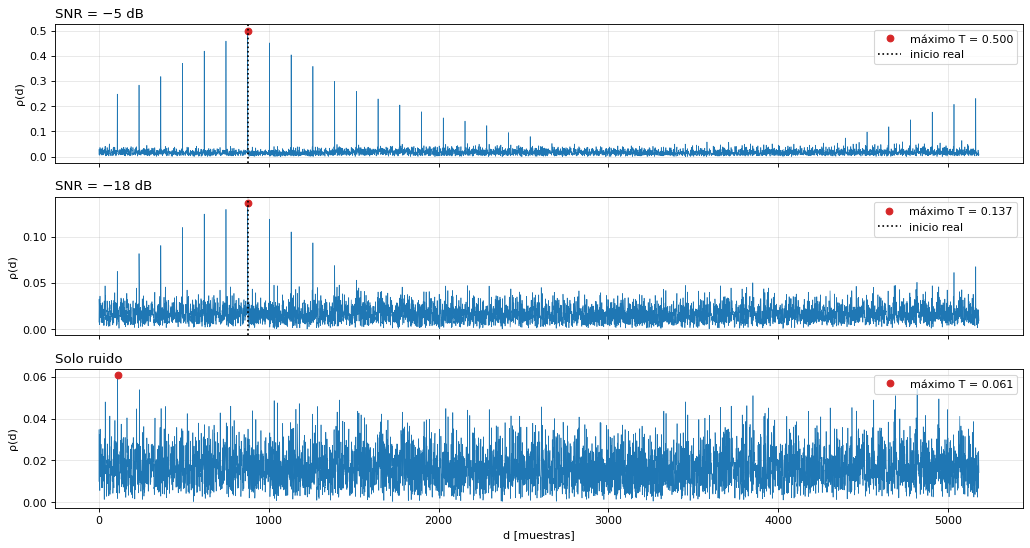

Se superpone el preámbulo `p` sobre la captura `r` en la posición `d`, se multiplica muestra a muestra, se suma y se normaliza por las energías:

$$\rho(d) = \frac{\left|\sum_{n=0}^{P-1} r[n+d]\; p^*[n]\right|}{\sqrt{\sum_{n} |p[n]|^2}\;\sqrt{\sum_{n} |r[n+d]|^2}}$$

Después se corre el patrón una muestra y se repite, para las `L` posiciones donde puede empezar la trama. La correlación se calcula en forma directa (`np.correlate`). ρ vale entre 0 y 1: es 1 cuando la ventana es una copia exacta del preámbulo, y no depende de la ganancia con que llega la señal. El estadístico de decisión es su máximo, `T = max ρ(d)`, y la posición del máximo es el inicio estimado.

- **SNR alta (−5 dB):** el máximo cae justo en el inicio real. Alrededor aparece una pirámide de picos laterales **cada 128 muestras**: el chirp del paper está formado por dos mitades iguales de 128 muestras (`c[n+128] = c[n]`), así que si el patrón se corre un múltiplo de 128 vuelve a coincidir con la señal salvo en los bordes, y la coincidencia baja de a 128 muestras por paso. Con cualquier otro corrimiento, el producto `r·p*` es un tono que se cancela al sumarlo, y ρ es casi cero.
- **SNR baja (−18 dB):** el máximo baja a ~0.13 y los picos laterales quedan casi a la misma altura: el detector puede equivocarse por múltiplos de 128 muestras.
- **Solo ruido:** el máximo no llega a 0.08. Con trama, en cambio, $T \approx \sqrt{\mathrm{SNR}/(1+\mathrm{SNR})}$. Sobre esa diferencia se elige el umbral.


Los 12 T más altos con solo ruido: [0.0754 0.0755 0.0755 0.0757 0.0762 0.0763 0.0785 0.079  0.0797 0.0801
 0.0814 0.0825]
Umbral: posición 9990 de 10000 -> γ = 0.0755 (teórico ≈ 0.0768)
El ruido solo supera γ en 10 de 10000 capturas
Con trama a -20 dB, T supera γ en el 96.6 % de las capturas
Con trama a -16 dB, T supera γ en el 100.0 % de las capturas


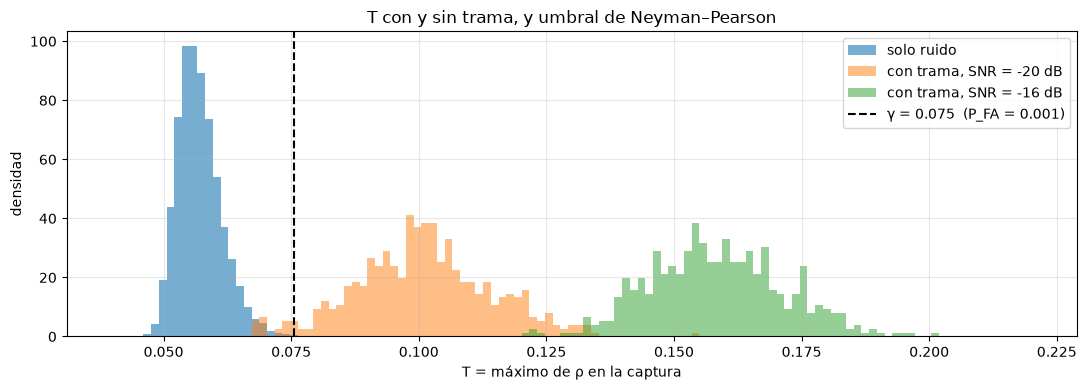

In [13]:
# DETECCIÓN — 3. Umbral del detector en el tiempo (Neyman-Pearson)
n_ruido = 10_000                    # capturas de solo ruido

generador_umbral = np.random.default_rng(semilla + 10)
T_ruido = np.array([detector_tiempo(generar_captura(0, generador_umbral, con_trama=False)[0], 1.0)[1]
                    for _ in range(n_ruido)])
T_ordenado = np.sort(T_ruido)                           # de menor a mayor
n_por_encima = int(round(P_FA * n_ruido))               # 1/1000 de 10 000 = 10 capturas
gamma = float(T_ordenado[n_ruido - n_por_encima - 1])   # posición 9990 (Python cuenta desde 0)
gamma_teorico = np.sqrt(np.log(L / P_FA) / P)
print(f"Los 12 T más altos con solo ruido: {np.round(T_ordenado[-12:], 4)}")
print(f"Umbral: posición {n_ruido - n_por_encima} de {n_ruido} -> γ = {gamma:.4f} "
      f"(teórico ≈ {gamma_teorico:.4f})")
print(f"El ruido solo supera γ en {np.sum(T_ruido > gamma)} de {n_ruido} capturas")

T_trama = {}
for snr in (-20, -16):
    g = np.random.default_rng(semilla + 20 + snr)
    T_trama[snr] = np.array([detector_tiempo(generar_captura(snr, g)[0], 1.0)[1] for _ in range(500)])
    print(f"Con trama a {snr} dB, T supera γ en el {np.mean(T_trama[snr] >= gamma) * 100:.1f} % de las capturas")

plt.figure(figsize=(11, 4))
bordes = np.linspace(0.04, 0.22, 120)
plt.hist(T_ruido, bordes, density=True, alpha=0.6, label="solo ruido")
for snr, valores in T_trama.items():
    plt.hist(valores, bordes, density=True, alpha=0.5, label=f"con trama, SNR = {snr} dB")
plt.axvline(gamma, color="k", linestyle="--", label=f"γ = {gamma:.3f}  (P_FA = {P_FA:g})")
plt.xlabel("T = máximo de ρ en la captura")
plt.ylabel("densidad")
plt.title("T con y sin trama, y umbral de Neyman–Pearson")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


<a id="umbral"></a>

**Umbral de decisión: criterio de Neyman–Pearson**

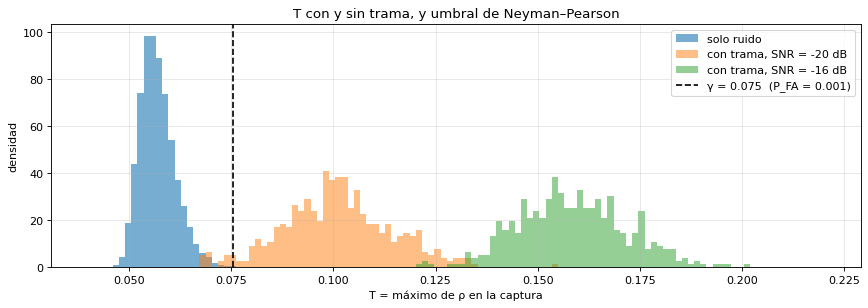

El umbral γ es el **"techo" del ruido**: hasta dónde llega `T` cuando no hay ninguna trama. Si en una captura `T` supera γ, el pico es más alto de lo que el ruido solo casi nunca alcanza → **hay trama**, y empieza en la posición del máximo. Si no lo supera → **no hay trama**.

Cómo se calcula γ:

1. Se simulan 10 000 capturas **de solo ruido** y en cada una se calcula `T`.
2. Se elige la probabilidad de falsa alarma aceptada, $P_{FA} = 10^{-3}$: 1 de cada 1000 capturas de ruido puede dar "hay trama". Es un parámetro de diseño; reducirla un orden de magnitud solo sube γ lo equivalente a ≈0,6 dB de sensibilidad, y con 10⁴ capturas de ruido el umbral se estima bien.
3. Se ordenan los 10 000 valores de `T` de menor a mayor. 1/1000 de 10 000 son 10 capturas, así que γ es el valor que deja solo 10 por encima: **el de la posición 9990**. Resulta **γ = 0.0755**, y coincide con la aproximación teórica $\gamma \approx \sqrt{\ln(L/P_{FA})/P} = 0.077$.

Como ρ está normalizado, `T` con solo ruido no depende de la potencia del ruido: γ se calcula una sola vez y sirve para cualquier SNR. En el histograma, `T` con solo ruido (azul) queda concentrado alrededor de 0.06. Con trama a −16 dB queda totalmente a la derecha de γ, y a −20 dB todavía lo supera en el 97 % de las capturas.


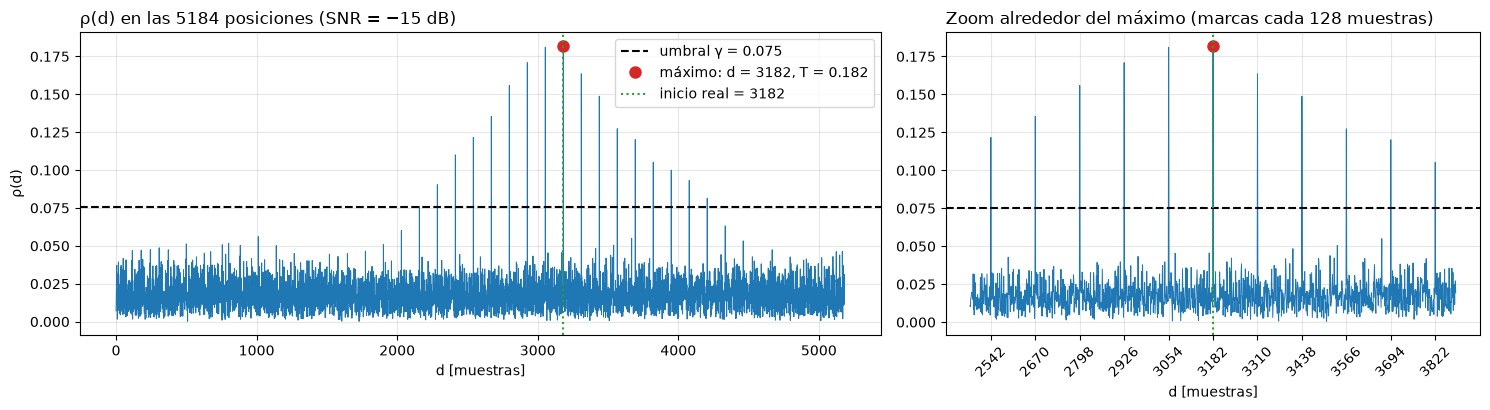

T = 0.182 ≥ γ = 0.075 -> hay trama, empieza en 3182 (real: 3182)


In [14]:
# DETECCIÓN — 4. La correlación justo antes de elegir el máximo
rho = correlacion_normalizada(x_ej)
d = int(np.argmax(rho))
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [3, 2]})
for eje, (a, b) in zip(ejes, [(0, L), (d - 700, d + 700)]):
    n = np.arange(max(a, 0), min(b, L))
    eje.plot(n, rho[n], linewidth=0.7)
    eje.axhline(gamma, color="k", linestyle="--", label=f"umbral γ = {gamma:.3f}")
    eje.plot(d, rho[d], "o", color="C3", markersize=8, label=f"máximo: d = {d}, T = {rho[d]:.3f}")
    eje.axvline(inicio_ej, color="C2", linestyle=":", label=f"inicio real = {inicio_ej}")
    eje.set_xlabel("d [muestras]")
    eje.grid(alpha=0.3)
ejes[0].set_ylabel("ρ(d)")
ejes[0].set_title("ρ(d) en las 5184 posiciones (SNR = −15 dB)", loc="left")
ejes[1].set_title("Zoom alrededor del máximo (marcas cada 128 muestras)", loc="left")
ejes[1].set_xticks(np.arange(d - 640, d + 641, 128))
ejes[1].tick_params(axis="x", labelrotation=45)
ejes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()
print(f"T = {rho[d]:.3f} {'≥' if rho[d] >= gamma else '<'} γ = {gamma:.3f} -> "
      f"{'hay trama, empieza en ' + str(d) if rho[d] >= gamma else 'no hay trama'} (real: {inicio_ej})")


<a id="decision"></a>

**La decisión sobre una captura**

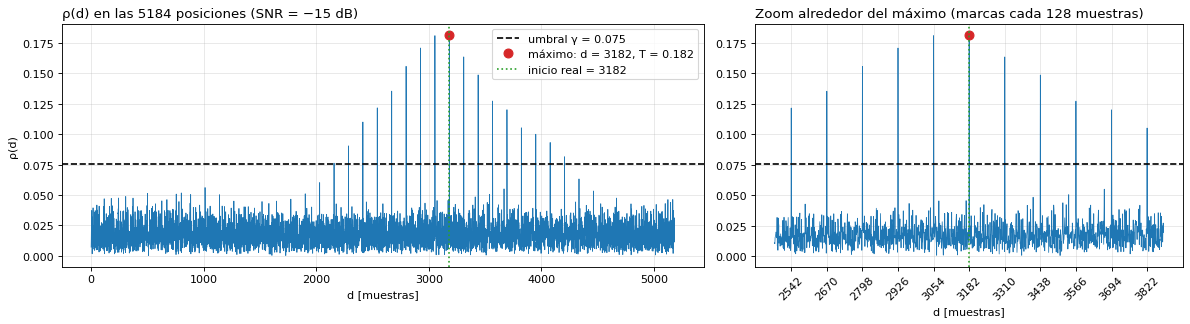

Así queda ρ(d) justo antes de elegir el máximo, en una captura a −15 dB. De las 5184 posiciones solo un puñado supera el umbral, todas alrededor de la trama: el pico verdadero y los picos laterales separados 128 muestras (las marcas del zoom). El detector se queda con el más alto, que es el inicio real, y como supera γ declara que hay trama. En el resto de la curva, donde el preámbulo no está alineado, ρ queda por debajo del umbral.


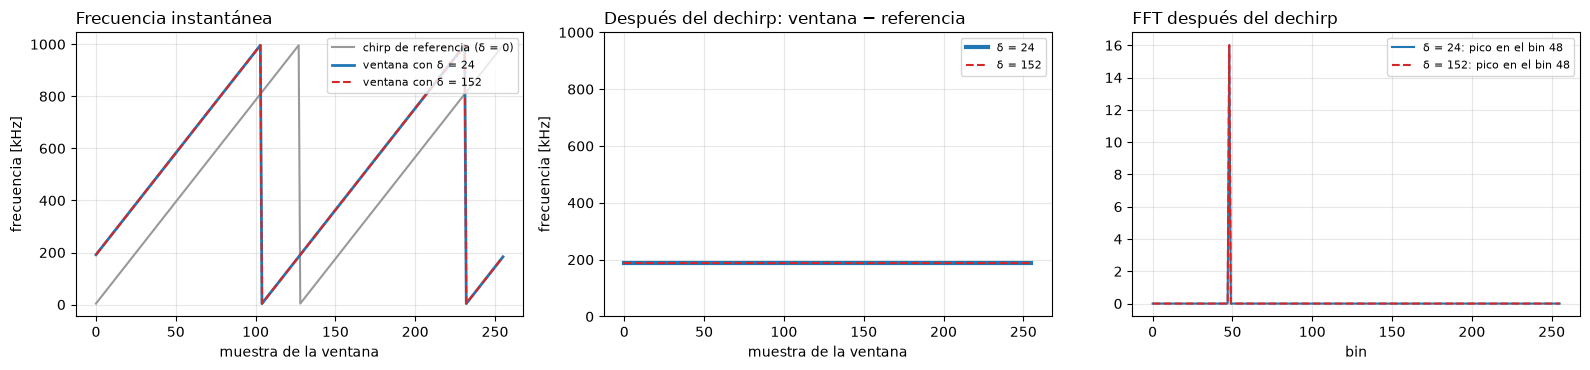

¿Las ventanas con δ = 24 y δ = 152 son iguales? True


In [15]:
# DETECCIÓN — 5. Detector en frecuencia: qué dice el bin de una ventana
def bins_por_ventana(captura_in):
    """Corta la captura en ventanas de M muestras, dechirp + FFT: (bin del pico, espectros)."""
    n_vent = captura_in.size // M
    ventanas = captura_in[: n_vent * M].reshape(n_vent, M) * DECHIRP
    espectro = np.abs(np.fft.fft(ventanas, axis=1))
    return np.argmax(espectro, axis=1), espectro


# Ventanas que empiezan delta muestras adentro de un up-chirp, sin ruido
dos_chirps = np.tile(up_chirp(M), 2)
n = np.arange(M)
f_inst = lambda delta: ((2 * (n + delta) + 1) / M % 1) * SamplingRate / 1e3   # kHz
fig, ejes = plt.subplots(1, 3, figsize=(16, 3.8))
ejes[0].plot(n, f_inst(0), color="0.6", label="chirp de referencia (δ = 0)")
ejes[0].plot(n, f_inst(24), color="C0", linewidth=2, label="ventana con δ = 24")
ejes[0].plot(n, f_inst(152), "--", color="C3", label="ventana con δ = 152")
ejes[0].set_title("Frecuencia instantánea", loc="left")
ejes[0].set_xlabel("muestra de la ventana")
ejes[0].set_ylabel("frecuencia [kHz]")
dif = lambda delta: (f_inst(delta) - f_inst(0)) % (SamplingRate / 1e3)
ejes[1].plot(n, dif(24), color="C0", linewidth=3, label="δ = 24")
ejes[1].plot(n, dif(152), "--", color="C3", label="δ = 152")
ejes[1].set_ylim(0, SamplingRate / 1e3)
ejes[1].set_title("Después del dechirp: ventana − referencia", loc="left")
ejes[1].set_xlabel("muestra de la ventana")
ejes[1].set_ylabel("frecuencia [kHz]")
for delta, estilo, color in ((24, "-", "C0"), (152, "--", "C3")):
    espectro = np.abs(np.fft.fft(dos_chirps[delta: delta + M] * down_chirp_demod(M)))
    ejes[2].plot(espectro, estilo, color=color, label=f"δ = {delta}: pico en el bin {np.argmax(espectro)}")
ejes[2].set_title("FFT después del dechirp", loc="left")
ejes[2].set_xlabel("bin")
for eje in ejes:
    eje.grid(alpha=0.3)
    eje.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()
print("¿Las ventanas con δ = 24 y δ = 152 son iguales?",
      np.allclose(dos_chirps[24: 24 + M], dos_chirps[152: 152 + M]))


<a id="bin"></a>

**Detector en frecuencia: qué dice el bin de una ventana**

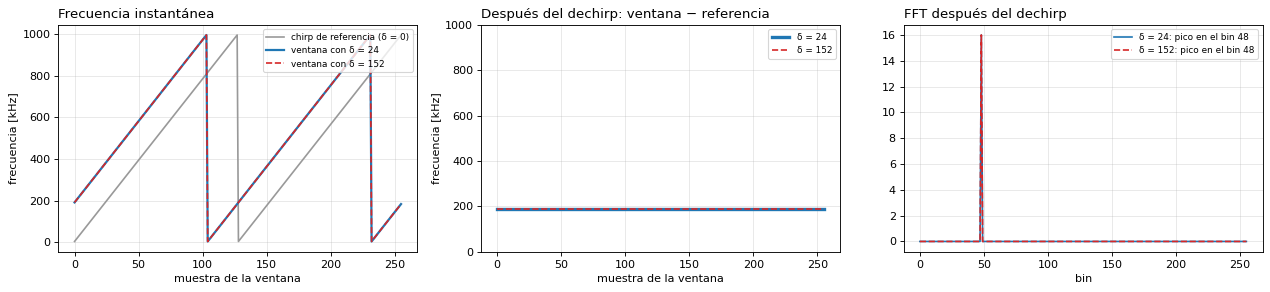

El detector en frecuencia corta la captura en ventanas de 256 muestras y demodula cada una como si fuera un símbolo: dechirp y FFT. La FFT de 256 puntos da 256 salidas, una por frecuencia, separadas 1 MHz / 256 ≈ 3,9 kHz: cada salida es un **bin**. Después del dechirp la ventana se convierte en un tono que cae en un solo bin; ese bin es el símbolo demodulado.

Las ventanas se cortan sin saber dónde está la trama, así que casi nunca caen alineadas con los chirps. Si una ventana empieza δ muestras adentro de un up-chirp, contiene el final de un chirp y el principio del siguiente, que es **el mismo chirp rotado**. Su frecuencia va siempre adelantada respecto del chirp de referencia en una cantidad fija (izquierda). El dechirp resta la frecuencia de la referencia y deja esa diferencia constante, un tono (centro), que la FFT pone en el bin `2δ` (derecha):

$$c[n+\delta]\,c^*[n] = e^{j2\pi\delta^2/M}\; e^{j2\pi (2\delta)\, n/M}$$

Por eso **el bin dice cuántas muestras está corrida la ventana**: bin 48 → δ = 24.

**La ambigüedad:** como el chirp del paper está formado por dos mitades iguales de 128 muestras, una ventana con δ = 24 y otra con δ = 152 contienen **exactamente las mismas muestras** (las curvas se superponen) y dan el mismo bin. El bin fija el inicio solo módulo 128 muestras.


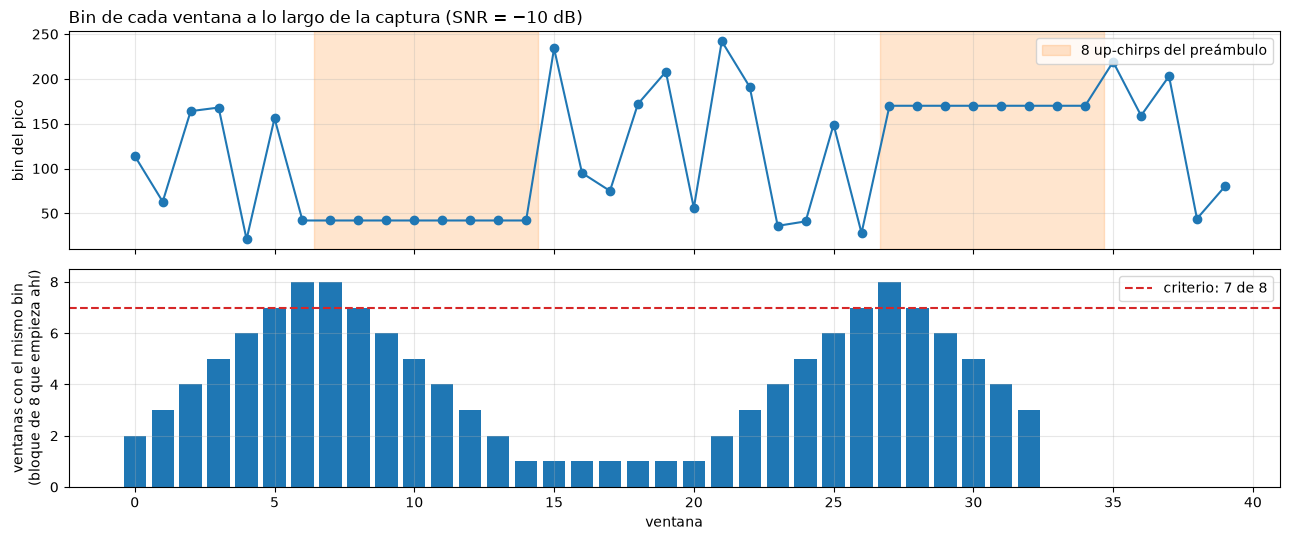

Inicio real 1643 | inicio estimado 1643


In [16]:
# DETECCIÓN — 6. Detector en frecuencia: criterio 7 de 8 y ubicación del inicio
def detector_frecuencia(captura_in, K=7):
    """Devuelve (inicio estimado o -1 si no hay trama, coincidencias por bloque, bins)."""
    bins, _ = bins_por_ventana(captura_in)
    bloques = np.lib.stride_tricks.sliding_window_view(bins, 8)
    coincidencias = (bloques[:, :, None] == bloques[:, None, :]).sum(axis=2).max(axis=1)
    if coincidencias.max() < K:
        return -1, coincidencias, bins
    b = int(np.argmax(coincidencias))
    valores, cuenta = np.unique(bloques[b], return_counts=True)
    bin_pre = int(valores[np.argmax(cuenta)])
    # bin = 2·delta (mod M): el inicio queda fijado módulo M/2 = 128 muestras.
    # La racha puede venir de cualquiera de las dos copias de la trama (±L).
    deltas = {bin_pre // 2, (bin_pre + 1) // 2}
    restos = np.unique([(-dl + s) % (M // 2) for dl in deltas for s in (0, L, -L)])
    cand = (restos[:, None] + np.arange(-(-L // (M // 2))) * (M // 2)).ravel()
    cand = cand[cand < L]
    # Desempate: correlación del preámbulo completo solo en los candidatos
    corr = np.abs(captura_in[cand[:, None] + np.arange(P)] @ np.conj(PRE))
    return int(cand[np.argmax(corr)]), coincidencias, bins


x_f, inicio_xf, _ = generar_captura(-10, np.random.default_rng(semilla + 3))
inicio_f, coincidencias, bins = detector_frecuencia(x_f)
_, espectro_f = bins_por_ventana(x_f)
fig, ejes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
ejes[0].plot(bins, "o-")
for copia in (0, L):
    ejes[0].axvspan((inicio_xf + copia) / M, (inicio_xf + copia + n_up * M) / M, color="C1", alpha=0.2,
                    label="8 up-chirps del preámbulo" if copia == 0 else None)
ejes[0].set_ylabel("bin del pico")
ejes[0].set_title("Bin de cada ventana a lo largo de la captura (SNR = −10 dB)", loc="left")
ejes[0].legend(loc="upper right")
ejes[0].grid(alpha=0.3)
ejes[1].bar(np.arange(coincidencias.size), coincidencias, color="C0")
ejes[1].axhline(7, color="C3", linestyle="--", label="criterio: 7 de 8")
ejes[1].set_xlabel("ventana")
ejes[1].set_ylabel("ventanas con el mismo bin\n(bloque de 8 que empieza ahí)")
ejes[1].set_ylim(0, 8.5)
ejes[1].legend(loc="upper right")
ejes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()
print(f"Inicio real {inicio_xf} | inicio estimado {inicio_f}")


<a id="criterio"></a>

**Criterio 7 de 8 y ubicación del inicio**

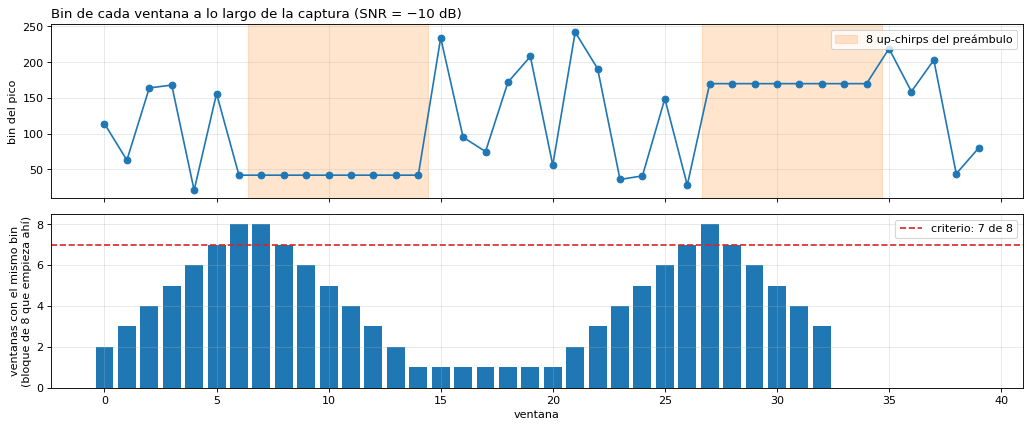

**Paso 1 — Bin de cada ventana (arriba).** La captura da 40 ventanas. Sobre los up-chirps del preámbulo todas las ventanas tienen el mismo δ, porque avanzan de a 256 muestras, lo mismo que dura un chirp: dan **el mismo bin**, una racha. En el payload y en el ruido los bins saltan. Hay dos rachas porque la captura tiene dos tramas, y la segunda da otro bin porque `L` no es múltiplo de 256.

**Paso 2 — Criterio (abajo).** Se recorren bloques de 8 ventanas seguidas. Si en un bloque **al menos 7 dan el mismo bin**, hay preámbulo. Se piden 7 y no 8 porque la primera o la última ventana puede caer en el borde del preámbulo (mitad up-chirp y mitad ruido, payload o down-chirp). Este criterio no necesita umbral: con solo ruido o payload, en un bloque coinciden como mucho 1 o 2 bins.

**Paso 3 — Inicio.** El bin da δ, y con él el inicio módulo 128 muestras: quedan unas 40 posiciones posibles. Para elegir la correcta se calcula la correlación con el preámbulo completo **solo en esas posiciones** y se toma la mayor. El preámbulo completo tiene bordes (termina con los down-chirps), así que solo en la posición correcta coincide en todo su largo. Son ~40 correlaciones en lugar de las 5184 del detector en el tiempo.


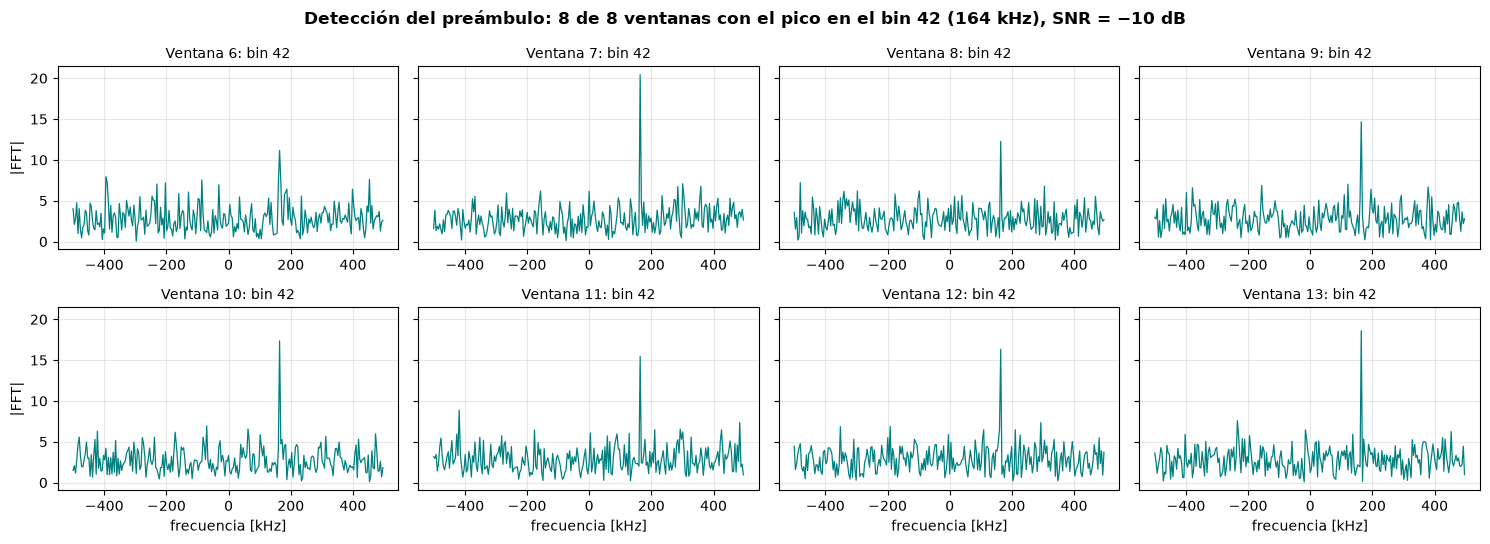

In [17]:
# DETECCIÓN — 7. Las 8 ventanas del bloque que cumplió el criterio
b = int(np.argmax(coincidencias))
bloque = bins[b: b + 8]
bin_pre = int(np.bincount(bloque).argmax())
f_khz = np.fft.fftshift(np.fft.fftfreq(M, 1 / SamplingRate)) / 1e3
fig, ejes = plt.subplots(2, 4, figsize=(15, 5.5), sharey=True)
for j, eje in enumerate(ejes.ravel()):
    v = b + j
    igual = bins[v] == bin_pre
    eje.plot(f_khz, np.fft.fftshift(espectro_f[v]), color="teal" if igual else "C3", linewidth=0.9)
    eje.set_title(f"Ventana {v}: bin {bins[v]}" + ("" if igual else "  (distinto)"), fontsize=10)
    eje.grid(alpha=0.3)
for eje in ejes[1]:
    eje.set_xlabel("frecuencia [kHz]")
for eje in ejes[:, 0]:
    eje.set_ylabel("|FFT|")
f_pico = f_khz[np.fft.fftshift(np.arange(M)) == bin_pre][0]
fig.suptitle(f"Detección del preámbulo: {int(np.sum(bloque == bin_pre))} de 8 ventanas con el pico en el "
             f"bin {bin_pre} ({f_pico:.0f} kHz), SNR = −10 dB", fontweight="bold")
fig.tight_layout()
plt.show()


<a id="ventanas"></a>

**Las 8 ventanas del bloque detectado**

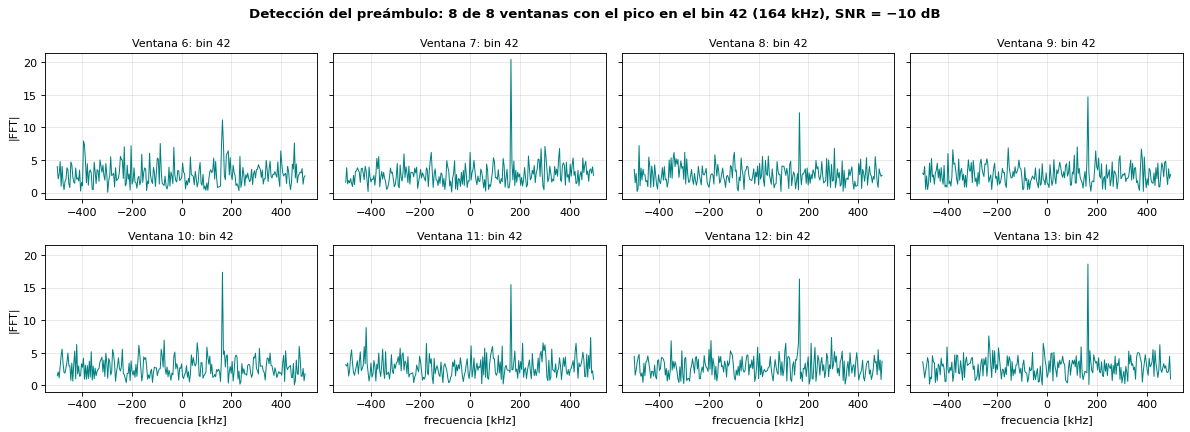

Cada panel es el espectro de una de las 8 ventanas seguidas que cumplieron el criterio, en la captura simulada a −10 dB. En las que caen sobre los up-chirps aparece un único pico, **siempre en la misma frecuencia**, muy por encima del ruido. El pico no está en 0 kHz porque las ventanas no están alineadas con el chirp: su posición indica cuántas muestras está corrida la ventana. Si alguna ventana cae en parte fuera de los up-chirps, su pico sale en otro bin (en rojo); por eso el criterio pide 7 de 8.


<a id="desempeno"></a>

## 3. Desempeño en simulación: FER y BER


In [ ]:
# FER — Detección + payload contra la SNR, canal FLAT y selectivo
# Cada captura la procesan los dos detectores. La trama se pierde si la detección
# falla o si algún símbolo del payload sale mal. Referencia: inicio conocido.
# Con 50 000 capturas por punto la simulación tarda varias horas: se guarda un
# checkpoint cada 500 capturas y, si se interrumpe, al volver a correr retoma.
import os


def simular_bloque(h, snr, generador, n):
    """Procesa n capturas. Devuelve [det_t, det_f, ok_t, ok_f, ok_ideal] y los tiempos de cada detector."""
    conteo = np.zeros(5, dtype=np.int64)
    t_t = t_f = 0.0
    for _ in range(n):
        x, ini, simb = generar_captura(snr, generador, h=h)
        conteo[4] += np.array_equal(demodular(x[ini + P: ini + L]), simb)      # inicio conocido
        a = time.perf_counter()
        d_t, _ = detector_tiempo(x, gamma)
        b = time.perf_counter()
        d_f, _, _ = detector_frecuencia(x)
        c = time.perf_counter()
        t_t += b - a
        t_f += c - b
        for j, d in enumerate((d_t, d_f)):
            if d == ini:
                conteo[j] += 1
                conteo[2 + j] += np.array_equal(demodular(x[d + P: d + L]), simb)
    return conteo, t_t, t_f


canales = (("FLAT", h_flat), ("selectivo", h_selectivo))
bloque_fer = 500
ruta_fer = "fer_detectores.npz"
conteos = np.zeros((len(canales), snr_fer_db.size, 5), dtype=np.int64)
hechas = np.zeros((len(canales), snr_fer_db.size), dtype=np.int64)
tiempos = np.zeros(3)                  # [s detector tiempo, s detector frecuencia, capturas medidas]
if os.path.exists(ruta_fer):
    datos = np.load(ruta_fer)
    if np.array_equal(datos["snr"], snr_fer_db) and np.isclose(float(datos["gamma"]), gamma):
        conteos, hechas, tiempos = datos["conteos"], datos["hechas"], datos["tiempos"]

t0 = time.time()
for ic, (canal, h) in enumerate(canales):
    for i, snr in enumerate(snr_fer_db):
        while hechas[ic, i] < n_capturas_fer:
            n = int(min(bloque_fer, n_capturas_fer - hechas[ic, i]))
            # Semilla fija por bloque: el resultado es el mismo aunque se interrumpa y retome
            g = np.random.default_rng([semilla, ic, i, int(hechas[ic, i]) // bloque_fer])
            c, t_t, t_f = simular_bloque(h, snr, g, n)
            conteos[ic, i] += c
            hechas[ic, i] += n
            tiempos += (t_t, t_f, n)
            np.savez(ruta_fer + ".tmp.npz", snr=snr_fer_db, gamma=gamma,
                     conteos=conteos, hechas=hechas, tiempos=tiempos)
            os.replace(ruta_fer + ".tmp.npz", ruta_fer)
            if hechas[ic, i] % 10_000 == 0:
                print(f"{canal:9s} SNR {snr:>3} dB: {hechas[ic, i]}/{n_capturas_fer} capturas")
print(f"Simulación: {time.time() - t0:.0f} s en esta ejecución | {int(hechas.sum())} capturas en total")

resultados = {}
for ic, (canal, _) in enumerate(canales):
    tasa = conteos[ic] / hechas[ic][:, None]
    resultados[canal] = {"pd_t": tasa[:, 0], "pd_f": tasa[:, 1], "fer_t": 1 - tasa[:, 2],
                         "fer_f": 1 - tasa[:, 3], "fer_ideal": 1 - tasa[:, 4]}
ms_t = tiempos[0] / tiempos[2] * 1e3
ms_f = tiempos[1] / tiempos[2] * 1e3

for canal, r in resultados.items():
    print(f"\nCanal {canal}")
    print(f"{'SNR':>5} {'P_D tiempo':>11} {'P_D frec':>9} {'FER tiempo':>11} {'FER frec':>9} {'FER ideal':>10}")
    for i, snr in enumerate(snr_fer_db):
        print(f"{snr:>5} {r['pd_t'][i]:>11.3f} {r['pd_f'][i]:>9.3f} {r['fer_t'][i]:>11.3f} "
              f"{r['fer_f'][i]:>9.3f} {r['fer_ideal'][i]:>10.3f}")

generador_fa = np.random.default_rng(semilla + 11)
fa_f = np.mean([detector_frecuencia(generar_captura(0, generador_fa, con_trama=False)[0])[0] >= 0
                for _ in range(n_ruido)])
print(f"\nFalsa alarma con {n_ruido} capturas de ruido: tiempo = {P_FA:g} (por construcción) | "
      f"frecuencia = {fa_f:g}")
print(f"Costo por captura: tiempo = {ms_t:.1f} ms | frecuencia = {ms_f:.2f} ms")

# Recortes solo para graficar (no afectan la simulación ni el checkpoint)
sel_pd = snr_fer_db <= -8      # P_D: de -24 a -8 dB
sel_fer = snr_fer_db >= -14    # FER: de -14 a -4 dB

# Probabilidad de detección
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
for eje, (canal, r) in zip(ejes, resultados.items()):
    eje.plot(snr_fer_db[sel_pd], r["pd_t"][sel_pd], "o-", linewidth=2, label=f"Tiempo (γ = {gamma:.3f})")
    eje.plot(snr_fer_db[sel_pd], r["pd_f"][sel_pd], "^-", linewidth=2, color="C1", label="Frecuencia (7 de 8)")
    eje.set_title(f"Probabilidad de detección — canal {canal}", loc="left")
    eje.set_xlabel("SNR = 10·log10(Ps/Pn) [dB]")
    eje.set_xticks(snr_fer_db[sel_pd])
    eje.set_xlim(snr_fer_db[sel_pd][0], -8)
    eje.set_ylim(-0.03, 1.03)
    eje.grid(alpha=0.3)
    eje.legend(loc="lower right")
ejes[0].set_ylabel("$P_D$")
fig.tight_layout()
plt.show()

# FER
piso = 1 / (2 * n_capturas_fer)     # para dibujar en escala log los puntos sin errores
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for eje, (canal, r) in zip(ejes, resultados.items()):
    eje.semilogy(snr_fer_db[sel_fer], np.maximum(r["fer_ideal"], piso)[sel_fer], "s--", color="0.5",
                 label="Inicio conocido (referencia)")
    eje.semilogy(snr_fer_db[sel_fer], np.maximum(r["fer_t"], piso)[sel_fer], "o-", linewidth=2, label="Detector en el tiempo")
    eje.semilogy(snr_fer_db[sel_fer], np.maximum(r["fer_f"], piso)[sel_fer], "^-", linewidth=2, color="C1",
                 label="Detector en frecuencia (7 de 8)")
    eje.axhline(piso, color="k", linewidth=0.6, linestyle=":")
    eje.set_title(f"FER — canal {canal} ({n_capturas_fer} tramas por punto)", loc="left")
    eje.set_xlabel("SNR = 10·log10(Ps/Pn) [dB]")
    eje.set_xticks(snr_fer_db[sel_fer])
    eje.set_xlim(-14, snr_fer_db[sel_fer][-1])
    eje.set_ylim(piso / 1.5, 1.5)
    eje.grid(True, which="both", alpha=0.3)
    eje.legend(loc="lower left")
ejes[0].set_ylabel("FER")
fig.tight_layout()
plt.show()

# Costo de cálculo
plt.figure(figsize=(8, 2.2))
plt.barh(["Frecuencia (7 de 8)", "Tiempo"], [ms_f, ms_t], color=["C1", "C0"])
for y, v in enumerate([ms_f, ms_t]):
    plt.text(v, y, f"  {v:.1f} ms", va="center")
plt.xlabel("ms por captura")
plt.title("Costo de cálculo por captura")
plt.xlim(0, ms_t * 1.25)
plt.tight_layout()
plt.show()


<a id="fer"></a>

**Detección y FER contra la SNR**

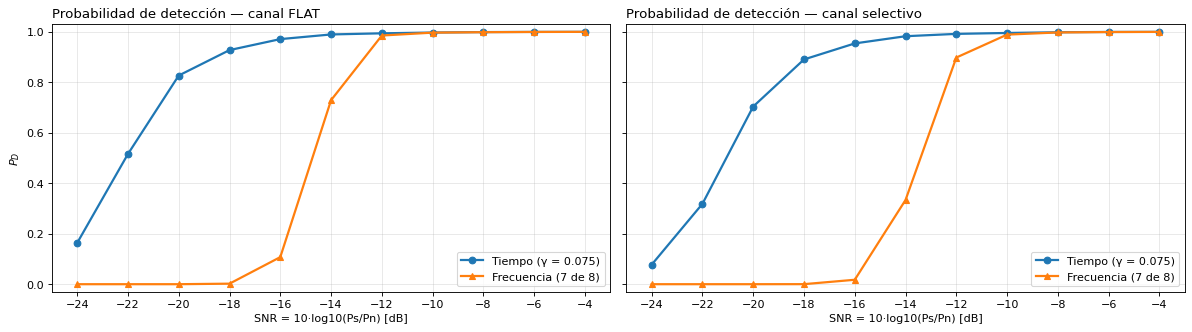

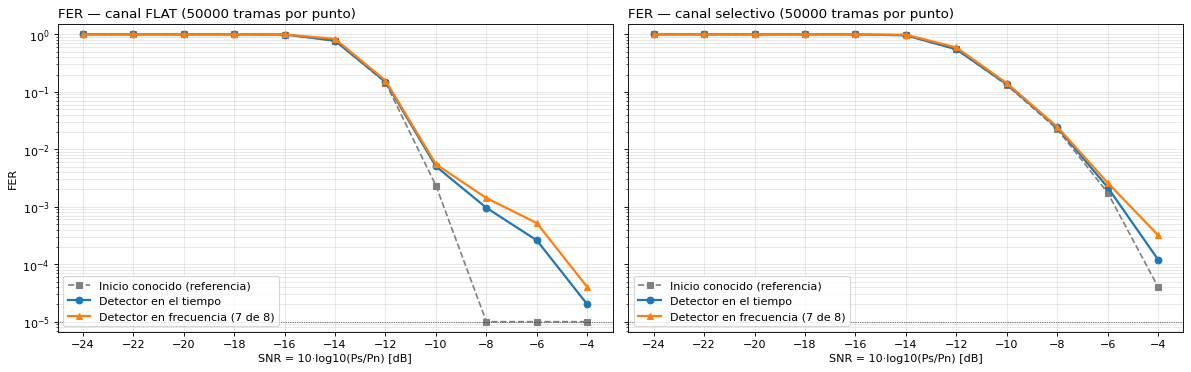

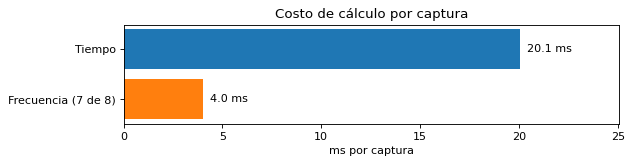

Para cada SNR se simulan **50 000 capturas**, en canal FLAT (`h = [1]`) y selectivo (`h = [√0.8, √0.2]`), y **los dos detectores procesan las mismas capturas**. Con 50 000 tramas se pueden medir FER de hasta ~10⁻⁴ (con 1000 tramas, cualquier valor por debajo de 10⁻³ aparecía como "sin errores"). La simulación completa tarda varias horas, así que la celda guarda un checkpoint (`fer_detectores.npz`) cada 500 capturas: si se interrumpe, al volver a correrla retoma desde ahí, y si ya terminó solo dibuja. Se mide:

- **Probabilidad de detección $P_D$:** el detector decide que hay trama **y** ubica el inicio exacto.
- **FER:** de las tramas enviadas, la fracción que se pierde porque no se detectó, se detectó en el lugar equivocado o algún símbolo del payload salió mal. Se compara con la FER que se obtendría **conociendo el inicio exacto** (referencia gris): la distancia a esa curva es lo que pierde cada detector.
- **Falsa alarma y costo:** con 10 000 capturas de solo ruido se cuenta cuántas veces el detector en frecuencia dice que hay trama (en el del tiempo es $P_{FA}$ por construcción), y se mide el tiempo de cálculo por captura.

Los puntos apoyados sobre la línea punteada son puntos **sin ningún error** en las 50 000 tramas. El eje es la SNR por muestra, `SNR = 10·log10(Ps/Pn)`. No es una reproducción de la Figura 1 del paper, que mide BER con SF = 7.

**Resultados**

- **Detección:** en canal FLAT, el detector en el tiempo encuentra la trama en el 83 % de las capturas a −20 dB y en el 99 % desde −14 dB. El de frecuencia casi no detecta hasta −18 dB, llega al 73 % a −14 dB y al 98,5 % a −12 dB: necesita unos **6 dB más de SNR**, porque decide ventana por ventana con la energía de un solo chirp (256 muestras), mientras que la correlación junta las 2624 muestras del preámbulo. En el canal selectivo los dos pierden 1 a 2 dB por el eco.
- **Falsa alarma:** en las 10 000 capturas de solo ruido, el criterio 7 de 8 nunca se cumplió. El detector en el tiempo tiene, por construcción, $P_{FA} = 10^{-3}$.
- **FER:** hasta −16 dB la FER es prácticamente 1 con los dos detectores **y también con el inicio conocido**: aunque el detector en el tiempo encuentre la trama, el payload no se puede demodular sin errores a esa SNR. En FLAT la FER cae a 77 % a −14 dB, 15 % a −12 dB y 0,5 % a −10 dB; el canal selectivo necesita unos 2 dB más (55 % a −12 dB, 14 % a −10 dB, 2,4 % a −8 dB). Hasta −10 dB los dos detectores quedan **pegados a la referencia**: la FER la fija la demodulación del payload.
- **Piso de los detectores:** con 50 000 tramas aparece algo que con 1000 no se veía. En FLAT, con el inicio conocido ya no hay errores desde −8 dB, pero con los detectores queda una FER de ~10⁻³ a −8 dB que baja a ~10⁻⁴–10⁻⁵ a −4 dB: tramas que se pierden **por la detección**, no por el payload. En el detector en el tiempo son siempre errores de **exactamente 128 muestras**: el pico lateral de la correlación (0,91 del pico verdadero) le gana al principal por el ruido. Es la misma ambigüedad de 128 muestras del chirp del paper. El detector en frecuencia tiene un piso algo mayor (1,4·10⁻³ a −8 dB) porque a esto se suma que alguna vez no se cumple el 7 de 8.
- **Costo:** el detector en el tiempo tarda unos 20 ms por captura y el de frecuencia 4 ms, unas **5 veces menos**. Los valores absolutos dependen de la computadora (en esta corrida eran dos simulaciones en paralelo); lo que importa es la relación entre los dos.

**Conclusión:** el detector en el tiempo es el más sensible, pero en la zona donde el payload se puede demodular (SNR ≥ −12 dB) los dos detectores dan prácticamente la misma FER: ahí el cuello de botella es la demodulación, no la detección. Solo a SNR alta, donde el payload ya casi no falla, se ve el piso de ~10⁻³ que agrega la detección, por la confusión de 128 muestras. El detector en frecuencia alcanza para el enlace y es bastante más liviano; el del tiempo solo hace falta para detectar tramas más débiles de las que se pueden demodular.


In [ ]:
# TRANSMISOR — 12. BER en simulación contra SNR (canal FLAT y selectivo)
# Cadena completa: bits -> símbolos -> chirps -> canal (convolución con h) + ruido
# -> dechirp + FFT -> símbolos -> bits. Se cuentan los bits distintos.
def simbolos_a_bits(simbolos, SF=SF):
    """Ecuación (1) invertida: devuelve los SF bits (LSB primero) de cada símbolo."""
    return (np.asarray(simbolos)[:, None] >> np.arange(SF)) & 1


def ber_simulada(h, snr_db, generador, simbolos_por_tanda=5000,
                 min_errores=100, max_bits=2_000_000):
    """BER para un canal h y una SNR = 10*log10(Ps/Pn) por muestra dada."""
    sigma_ruido = np.sqrt((1 / M) / 10 ** (snr_db / 10) / 2)   # Ps = 1/M, Pn = 2*sigma^2
    errores = 0
    enviados = 0
    while errores < min_errores and enviados < max_bits:
        bits_tx = generador.integers(0, 2, size=(simbolos_por_tanda, SF))
        simbolos_tx = bits_tx @ (2 ** np.arange(SF))       # ecuación (1)
        fase = 2 * np.pi * ((simbolos_tx[:, None] + k) % M) * k / M
        senal = (np.exp(1j * fase) / np.sqrt(M)).ravel()   # ecuaciones (2)-(3)
        # Los símbolos van uno detrás de otro: la cola del eco cae en el siguiente.
        recibida = np.convolve(senal, h)[: senal.size]
        recibida = recibida + sigma_ruido * (generador.standard_normal(senal.size)
                                             + 1j * generador.standard_normal(senal.size))
        simbolos_rx = demodular(recibida)                  # ecuaciones (15)-(16)
        bits_rx = simbolos_a_bits(simbolos_rx)
        errores += int(np.count_nonzero(bits_rx != bits_tx))
        enviados += bits_tx.size
    return errores / enviados, enviados


h_flat = np.array([1.0])                               # mismo canal que la FER
h_selectivo = np.array([np.sqrt(0.8), np.sqrt(0.2)])
# La BER necesita más SNR que la detección del preámbulo: cada bit depende de
# un solo símbolo, mientras que el preámbulo junta la energía de 10,25 símbolos.
snr_ber_db = np.arange(-4, 11, 1) - 10 * np.log10(M / SF)   # SNR por muestra: -19 a -5 dB
ber_minima = 1e-5               # por debajo de esto la curva se corta

generador_ber = np.random.default_rng(semilla + 7)
curvas_ber = {}
for nombre, h in (("FLAT", h_flat), ("selectivo", h_selectivo)):
    snrs, bers = [], []
    for snr in snr_ber_db:
        ber, bits = ber_simulada(h, snr, generador_ber)
        print(f"{nombre:9s} SNR {snr:>3.0f} dB: BER = {ber:.2e} ({bits} bits)")
        if ber < ber_minima:
            break
        snrs.append(snr)
        bers.append(ber)
    curvas_ber[nombre] = (snrs, bers)

plt.figure(figsize=(7, 4.5))
plt.semilogy(*curvas_ber["FLAT"], "o-", label="FLAT (solo ruido)")
plt.semilogy(*curvas_ber["selectivo"], "s-", label="selectivo (2 taps)")
plt.xlabel("SNR = 10·log10(Ps/Pn) [dB]")
plt.ylabel("BER")
plt.title("BER de LoRa (FSCM) en simulación")
plt.xticks(np.round(snr_ber_db))
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

<a id="ber"></a>

**BER contra la SNR**

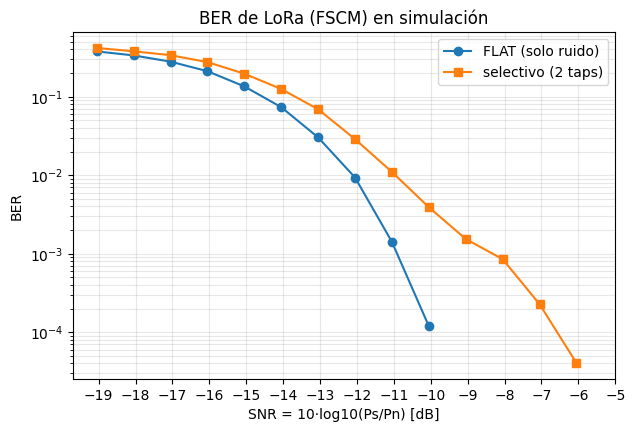

Se simula la cadena completa del enlace, de bits a bits: los bits aleatorios se convierten en símbolos (ecuación (1)), se modulan como chirps (ecuaciones (2)-(3)), pasan por el canal y se les suma ruido gaussiano complejo (ecuación (10)); el receptor aplica dechirp + FFT (ecuaciones (15)-(16)) y vuelve a convertir los símbolos en bits. La BER es la fracción de bits recibidos distintos de los enviados. Los canales son los mismos que en la FER, modelados por convolución: `h = [1]` para FLAT y `h = [√0.8, √0.2]` para selectivo. Los símbolos se transmiten uno detrás de otro, así que la cola del eco de un símbolo cae sobre el siguiente. Cada punto se simula hasta juntar 100 bits erróneos o 2 millones de bits, y la curva se corta cuando la BER baja de 10⁻⁵.

El eje usa la misma SNR por muestra que la FER, `SNR = 10·log10(Ps/Pn)`, de −19 a −5 dB, pero con otro rango: la BER depende de cada símbolo por separado, mientras que la detección del preámbulo junta la energía de 10,25 símbolos, así que la BER necesita más SNR. El canal selectivo necesita unos 3 a 4 dB más que el FLAT para llegar a la misma BER. Es el mismo tipo de comparación que la Figura 1 del paper, que también usa SNR por muestra, pero con SF = 7; acá se usa SF = 8.

<a id="enlace"></a>

## 4. Enlace real con el ADALM-Pluto


In [18]:
# CONFIGURACIÓN DEL SDR — se deja el enlace abierto para el receptor
import adi

sdr = adi.Pluto("ip:192.168.1.34")

# Si otra sesión dejó el chip en "alert", el RX no entrega muestras.
if sdr._ctrl.attrs["ensm_mode"].value != "fdd":
    sdr._ctrl.attrs["ensm_mode"].value = "fdd"

sdr.loopback = 0
sdr.sample_rate = int(SamplingRate)
sdr.tx_rf_bandwidth = 2_000_000
sdr.rx_rf_bandwidth = 2_000_000
sdr.tx_hardwaregain_chan0 = -60
sdr.gain_control_mode_chan0 = "slow_attack"
sdr.tx_lo = int(fc)
sdr.rx_lo = int(fc)
sdr.rx_buffer_size = tramas_en_buffer * longitud_trama()
sdr.tx_cyclic_buffer = True

print(f"Enlace configurado: {fc/1e6:.0f} MHz | RX buffer {sdr.rx_buffer_size} muestras")
print("El buffer cíclico se activa antes de transmitir.")

Enlace configurado: 915 MHz | RX buffer 10368 muestras
El buffer cíclico se activa antes de transmitir.


<a id="config-sdr"></a>

**Configuración del SDR**

Se establece la conexión con el ADALM-PLUTO del grupo y se lo prepara para transmitir y recibir al mismo tiempo. Las dos portadoras se fijan en 915 MHz, la tasa de muestreo en 1 MHz y la potencia de transmisión en un valor bajo. La ganancia de recepción la ajusta automáticamente el control de ganancia del Pluto. Cada captura alcanza para dos tramas, de modo que siempre queda al menos una completa adentro. Por último se activa el modo cíclico, que permite que la trama se repita sola una vez enviada.

In [19]:
# ENVÍO DE LA SEÑAL AL SDR
sdr.tx(trama * (2 ** 15 - 1))
print("Trama transmitida; el buffer cíclico la repite sin pausa.")

Trama transmitida; el buffer cíclico la repite sin pausa.


<a id="envio"></a>

**Envío de la trama**

La trama se escala al rango de enteros de 16 bits que espera el conversor del Pluto y se envía una sola vez. Gracias al modo cíclico, el SDR la retransmite sin pausa, una tras otra, sin que el programa tenga que volver a mandarla. El enlace queda abierto para que el receptor pueda capturar la señal en cualquier momento.

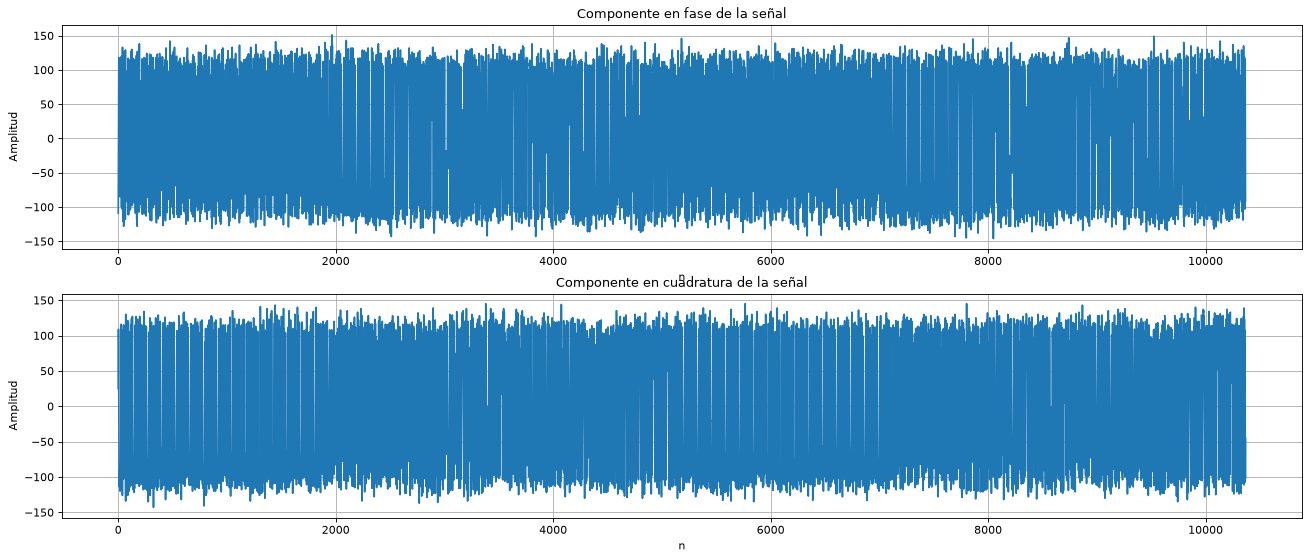

In [20]:
# RECEPTOR — 1. Gráfico de la señal recibida
captura = sdr.rx()
plotSignal(captura)

<a id="senal-rx"></a>

**Señal recibida en el dominio del tiempo**

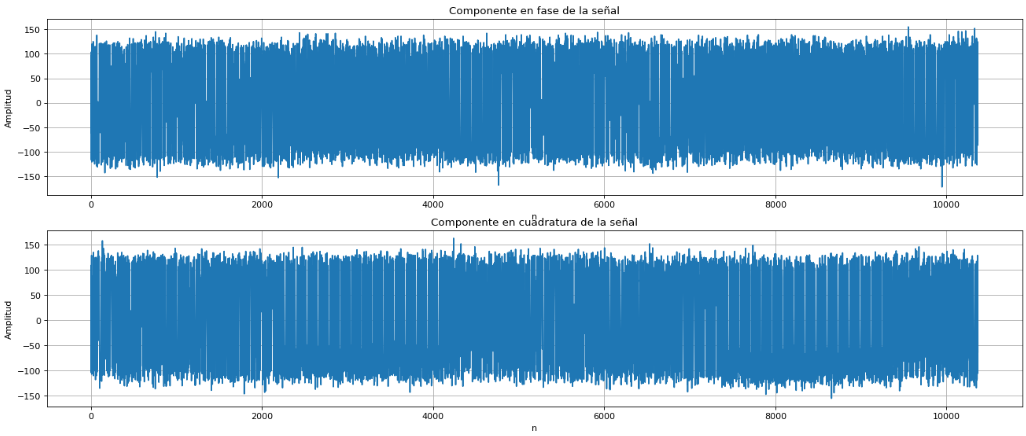

Se grafica la captura real del receptor: dos tramas consecutivas con preámbulo, payload y ruido. La amplitud depende de la ganancia y del AGC del Pluto. La señal recibida responde al modelo de la ecuación (10). Es la entrada de los dos detectores de la sección de detección; a simple vista el preámbulo puede quedar tapado por el ruido, y por eso hace falta buscarlo con la correlación o con la demodulación por ventanas.


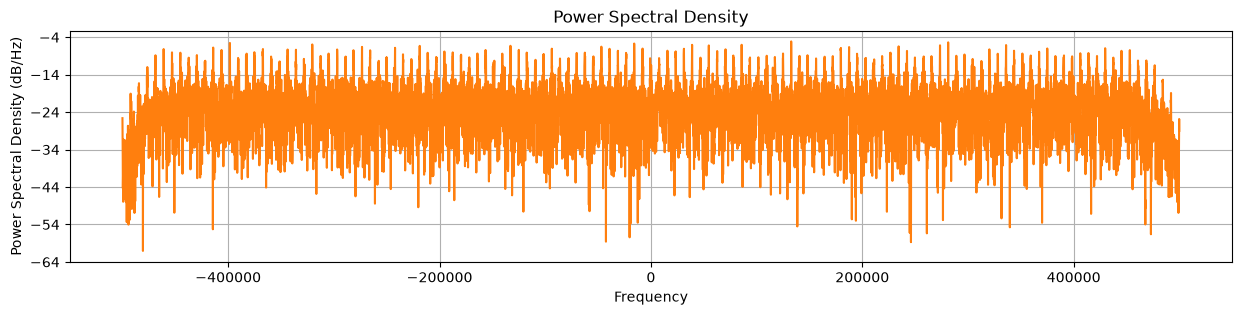

In [21]:
# RECEPTOR — 2. Densidad espectral de potencia de la señal recibida
plotSpect(captura, SamplingRate)

<a id="psd-rx"></a>

**Densidad espectral de potencia de la señal recibida**

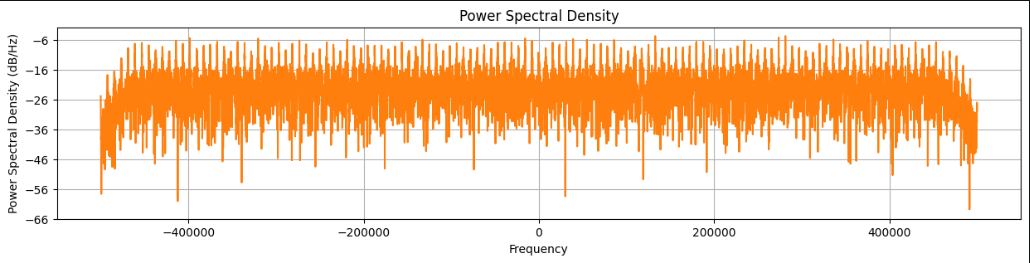

La PSD de la captura muestra la señal ocupando aproximadamente 1 MHz y un piso de ruido repartido en la banda. Es la versión experimental de la ecuación (10): señal más ruido blanco. Comparada con la PSD de la celda 8, permite ver cuánto ruido agregó el enlace y si la señal sigue dentro del ancho de banda esperado.


Detector en el tiempo:  T = 0.759 (γ = 0.075) -> inicio 5071
Detector en frecuencia: inicio 5071
Inicio de la trama: muestra 5071
Símbolos transmitidos: [194, 19, 225, 25, 62, 212, 49, 80, 38, 40]
Símbolos recibidos:    [194, 19, 225, 25, 62, 212, 49, 80, 38, 40]
Símbolos erróneos: 0/10 | bits erróneos: 0/80
Payload recuperado sin errores.


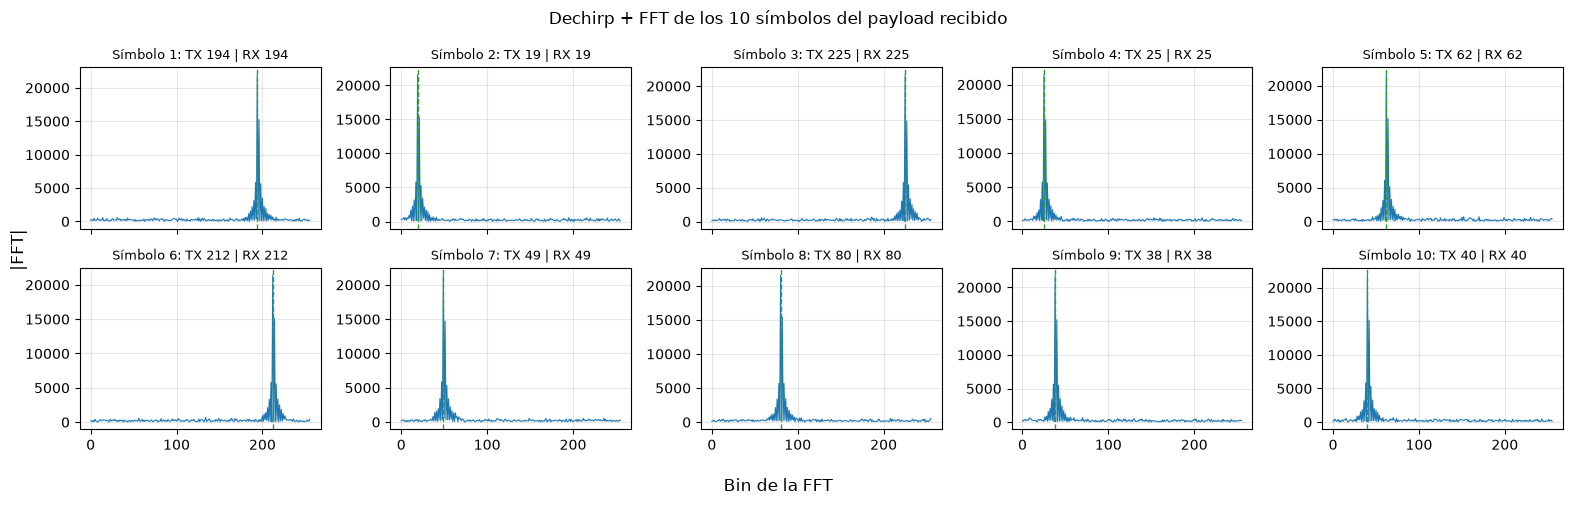

In [22]:
# RECEPTOR — 3. Detección y demodulación del payload de la captura
# Usa la captura del bloque "RECEPTOR — 1" (dos tramas) y los dos detectores de la
# sección DETECCIÓN. El inicio se busca entre 0 y L - 1: así el payload siempre entra
# completo en la captura.
largo_trama = longitud_trama()
largo_preambulo = longitud_preambulo()

inicio_t, T_rx = detector_tiempo(captura, gamma)
inicio_f, _, _ = detector_frecuencia(captura)
print(f"Detector en el tiempo:  T = {T_rx:.3f} (γ = {gamma:.3f}) -> "
      f"{'inicio ' + str(inicio_t) if inicio_t >= 0 else 'no hay trama'}")
print(f"Detector en frecuencia: {'inicio ' + str(inicio_f) if inicio_f >= 0 else 'no hay trama'}")
inicio_rx = inicio_t if inicio_t >= 0 else inicio_f
if inicio_rx < 0:
    raise RuntimeError("Ningún detector encontró la trama en la captura.")
comienzo_payload = inicio_rx + largo_preambulo
payload_rx = captura[comienzo_payload: comienzo_payload + n_simbolos * M]

simbolos_rx = demodular(payload_rx)                       # dechirp + FFT + argmax
bits_rx = (simbolos_rx[:, None] >> np.arange(SF)) & 1     # ecuación (1) invertida

errores_simbolo = int(np.count_nonzero(simbolos_rx != simbolos_payload))
errores_bit = int(np.count_nonzero(bits_rx != bits_payload))
print(f"Inicio de la trama: muestra {inicio_rx}")
print(f"Símbolos transmitidos: {simbolos_payload.tolist()}")
print(f"Símbolos recibidos:    {simbolos_rx.tolist()}")
print(f"Símbolos erróneos: {errores_simbolo}/{n_simbolos} | "
      f"bits erróneos: {errores_bit}/{n_simbolos * SF}")
print("Payload recuperado sin errores." if errores_simbolo == 0
      else "El payload llegó con errores.")

# Espectro de cada símbolo después del dechirp: el pico es el símbolo decidido.
espectros_rx = np.abs(np.fft.fft(payload_rx.reshape(n_simbolos, M)
                                 * down_chirp_demod(M), axis=1))
fig, ejes = plt.subplots(2, 5, figsize=(16, 5), sharex=True)
for i, eje in enumerate(ejes.ravel()):
    eje.plot(espectros_rx[i], linewidth=0.8)
    eje.axvline(simbolos_payload[i], color="C2", linestyle="--", linewidth=1)
    eje.set_title(f"Símbolo {i + 1}: TX {simbolos_payload[i]} | RX {simbolos_rx[i]}",
                  fontsize=9)
    eje.grid(alpha=0.3)
fig.supxlabel("Bin de la FFT")
fig.supylabel("|FFT|")
fig.suptitle("Dechirp + FFT de los 10 símbolos del payload recibido")
fig.tight_layout()
plt.show()

<a id="demod-rx"></a>

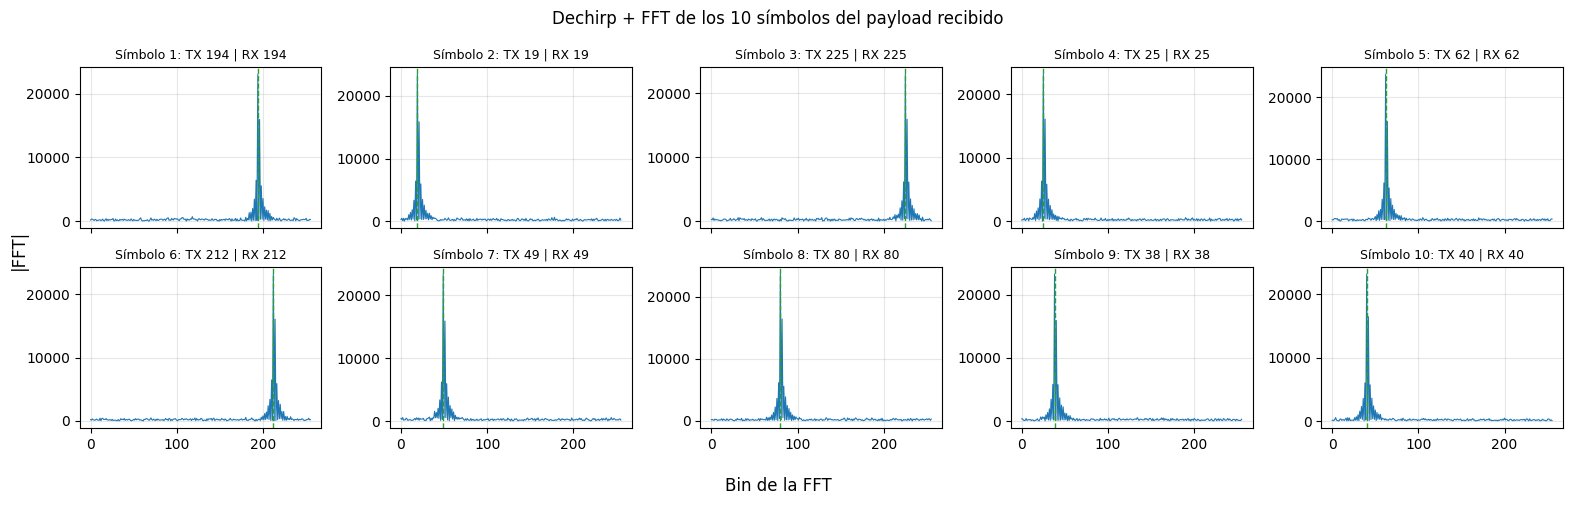
**Demodulación del payload recibido**

Con la trama ubicada, el receptor recupera el mensaje. Primero la buscan los dos detectores de la sección de detección: el del tiempo (correlación normalizada contra el umbral γ) y el de frecuencia (7 de 8 ventanas con el mismo bin). Se usa el inicio del detector en el tiempo, que es el más sensible; si no detecta, el de frecuencia. El inicio se busca entre 0 y L − 1, así el payload entra completo en la captura. A partir de ahí se saltean las 2624 muestras del preámbulo y se cortan 10 bloques de 256 muestras. Cada bloque se multiplica por el down-chirp y se le aplica la FFT; la posición del pico es el símbolo (ecuaciones (15) y (16)). Los símbolos se convierten en bits con la ecuación (1) invertida y se comparan con los transmitidos, contando símbolos y bits erróneos. El gráfico muestra el espectro de cada símbolo después del dechirp: la línea punteada marca el símbolo transmitido y, si llegó bien, coincide con el pico.


In [23]:
# RECEPTOR — 4. FER con 20000 capturas y tabla de resultados
# Cada captura la procesan los dos detectores. La trama cuenta como recibida si el
# detector la encuentra y los 10 símbolos demodulados coinciden con los transmitidos.
from IPython.display import Markdown, display

n_tramas_enlace = 20000
largo_trama = longitud_trama()
largo_preambulo = longitud_preambulo()
resumen = {nombre: {"sin_deteccion": 0, "payload_mal": 0, "correctas": 0}
           for nombre in ("tiempo", "frecuencia")}

t0 = time.time()
for indice in range(n_tramas_enlace):
    captura = sdr.rx()                 # 2 tramas: preámbulo + payload
    inicios = {"tiempo": detector_tiempo(captura, gamma)[0],
               "frecuencia": detector_frecuencia(captura)[0]}
    for nombre, inicio in inicios.items():
        if inicio < 0:
            resumen[nombre]["sin_deteccion"] += 1
        elif np.array_equal(demodular(captura[inicio + largo_preambulo: inicio + largo_trama]),
                            simbolos_payload):
            resumen[nombre]["correctas"] += 1
        else:
            resumen[nombre]["payload_mal"] += 1
    if (indice + 1) % 2000 == 0:
        print(f"{indice + 1}/{n_tramas_enlace} capturas")

filas = ["| Detector | Capturas | Sin detección | Detectada, payload con errores | Tramas correctas | FER |",
         "|---|---|---|---|---|---|"]
for nombre, r in resumen.items():
    perdidas = r["sin_deteccion"] + r["payload_mal"]
    fer_txt = f"{perdidas / n_tramas_enlace:.2e}" if perdidas else f"0 (< {1 / n_tramas_enlace:.0e})"
    filas.append(f"| {nombre.capitalize()} | {n_tramas_enlace} | {r['sin_deteccion']} | "
                 f"{r['payload_mal']} | {r['correctas']} | {fer_txt} |")
display(Markdown("\n".join(filas)))
print(f"Duración de la medición: {(time.time() - t0) / 60:.1f} min")


2000/20000 capturas
4000/20000 capturas
6000/20000 capturas
8000/20000 capturas
10000/20000 capturas
12000/20000 capturas
14000/20000 capturas
16000/20000 capturas
18000/20000 capturas
20000/20000 capturas


| Detector | Capturas | Sin detección | Detectada, payload con errores | Tramas correctas | FER |
|---|---|---|---|---|---|
| Tiempo | 20000 | 0 | 0 | 20000 | 0 (< 5e-05) |
| Frecuencia | 20000 | 0 | 0 | 20000 | 0 (< 5e-05) |

Duración de la medición: 41.7 min


<a id="fer-real"></a>

**FER en el enlace real**

Se mide la FER sobre la señal real con los mismos dos detectores y los mismos criterios que en la simulación: el umbral γ de Neyman–Pearson para el detector en el tiempo y 7 de 8 ventanas para el de frecuencia. Como el transmisor repite siempre la misma trama, cada captura es una nueva observación del mismo paquete, y como el payload transmitido es conocido se puede verificar la trama completa: cuenta como recibida si el detector la encuentra **y** los 10 símbolos demodulados coinciden con los transmitidos. Así la FER del enlace mide lo mismo que la FER simulada (detección + payload). Se toman 20 000 capturas; la medición tarda alrededor de media hora.

Al terminar, la celda muestra una tabla que separa las tramas perdidas en dos causas: **sin detección** (el detector no encontró la trama) y **payload con errores** (la encontró, pero algún símbolo salió mal).

**Resultados de la medición**:

| Detector | Capturas | Sin detección | Detectada, payload con errores | Tramas correctas | FER |
|---|---|---|---|---|---|
| Tiempo | 20 000 | 0 | 0 | 20000 | 0 (< 5e-05) |
| Frecuencia | 20 000 | 0 | 0 | 20000 | 0 (< 5e-05) |


In [ ]:
# CIERRE DEL ENLACE — dejar el Pluto atenuado y fuera de la banda
sdr.tx_destroy_buffer()
sdr.tx_hardwaregain_chan0 = -89
sdr.tx_lo = int(2400e6)
sdr.rx_lo = int(950e6)
sdr.tx(np.zeros(2048, dtype=np.complex128))
print("Enlace cerrado: TX atenuado y portadoras fuera de la banda.")

<a id="cierre"></a>

**Cierre del enlace**

Durante toda la práctica el Pluto estuvo transmitiendo la trama sin interrupción: el buffer cíclico la repite por su cuenta, sin que el programa tenga que volver a enviarla. Por eso terminar de ejecutar el notebook no detiene la transmisión, y este bloque se encarga de apagar el transmisor de forma ordenada. Primero se libera el buffer, con lo que la trama deja de repetirse. Como el Pluto no tiene una orden para apagarse, después se baja la potencia de salida al mínimo y se mueven las frecuencias de transmisión y recepción fuera de la banda de 900–920 MHz, que comparten los demás grupos. Por último se envían ceros, así lo único que queda emitiendo es silencio.